In [1]:
!pip install pystac planetary-computer rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.8 MB/s eta 0:00:00
  Attempting uninstall: xarray
    Found existing installation: xarray 2025.12.0
    Uninstalling xarray-2025.12.0:
      Successfully uninstalled xarray-2025.12.0


In [2]:
import pystac
import planetary_computer
import rioxarray

In [6]:
item_url = "https://planetarycomputer.microsoft.com/api/stac/v1/collections/sentinel-2-l2a/items/S2A_MSIL2A_20260916T083521_R021_T36RVU_20260916T132413"

item = pystac.Item.from_file(item_url)

signed_item = planetary_computer.sign(item)

print("تم تحميل الصورة بنجاح ✅")

تم تحميل الصورة بنجاح ✅


In [7]:
red = rioxarray.open_rasterio(
    signed_item.assets["B04"].href
).squeeze()

nir = rioxarray.open_rasterio(
    signed_item.assets["B08"].href
).squeeze()

print("Red و NIR اتحملوا بنجاح ✅")

Red و NIR اتحملوا بنجاح ✅


In [8]:
ndvi = (nir - red) / (nir + red)

ndvi

<xarray.DataArray (y: 10980, x: 10980)> Size: 964MB
array([[0.06866637, 0.1391839 , 0.10762917, ..., 0.04678122, 0.04731436,
        0.04494478],
       [0.06111908, 0.10244648, 0.10459635, ..., 0.05601811, 0.05475173,
        0.04936835],
       [0.08506363, 0.11830065, 0.09498754, ..., 0.05124047, 0.05020484,
        0.04887097],
       ...,
       [0.04477036, 0.04589279, 0.04795978, ..., 0.0593756 , 0.05923732,
        0.05889792],
       [0.04456532, 0.04742933, 0.04589441, ..., 0.05703565, 0.05766782,
        0.06327299],
       [0.04424946, 0.04427083, 0.04266033, ..., 0.06406323, 0.05761354,
        0.06650071]])
Coordinates:
  * y            (y) float64 88kB 3.4e+06 3.4e+06 3.4e+06 ... 3.29e+06 3.29e+06
  * x            (x) float64 88kB 4e+05 4e+05 4e+05 ... 5.097e+05 5.098e+05
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [9]:
import pystac
import planetary_computer
import rioxarray

item_url = "https://planetarycomputer.microsoft.com/api/stac/v1/collections/sentinel-2-l2a/items/S2A_MSIL2A_20260916T083521_R021_T36RVU_20260916T132413"

item = pystac.Item.from_file(item_url)
signed_item = planetary_computer.sign(item)

red = rioxarray.open_rasterio(
    signed_item.assets["B04"].href
).squeeze()

print("CRS:", red.rio.crs)

CRS: EPSG:32636


In [10]:
from pyproj import Transformer

# AOI point
lon = 32.197409
lat = 30.545972

# Convert from GPS coordinates (lat/lon) to Sentinel-2 coordinates
transformer = Transformer.from_crs(
    "EPSG:4326",
    red.rio.crs,
    always_xy=True
)

x, y = transformer.transform(lon, lat)

print("X:", x)
print("Y:", y)

X: 423017.9617508978
Y: 3379560.030211411


In [11]:
# مساحة صغيرة حول الـ AOI
size = 5000  # 5000 متر = 5 كم

x_min = x - size
x_max = x + size
y_min = y - size
y_max = y + size

print("X range:", x_min, "to", x_max)
print("Y range:", y_min, "to", y_max)

X range: 418017.9617508978 to 428017.9617508978
Y range: 3374560.030211411 to 3384560.030211411


In [12]:
red_aoi = red.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("B04 cropped successfully ✅")
print(red_aoi.shape)

B04 cropped successfully ✅
(1001, 1001)


In [13]:
nir = rioxarray.open_rasterio(
    signed_item.assets["B08"].href
).squeeze()

nir_aoi = nir.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("B08 cropped successfully ✅")
print(nir_aoi.shape)

B08 cropped successfully ✅
(1001, 1001)


In [14]:
ndvi_aoi = (nir_aoi - red_aoi) / (nir_aoi + red_aoi)

print("NDVI calculated successfully ✅")
print(ndvi_aoi.shape)

NDVI calculated successfully ✅
(1001, 1001)


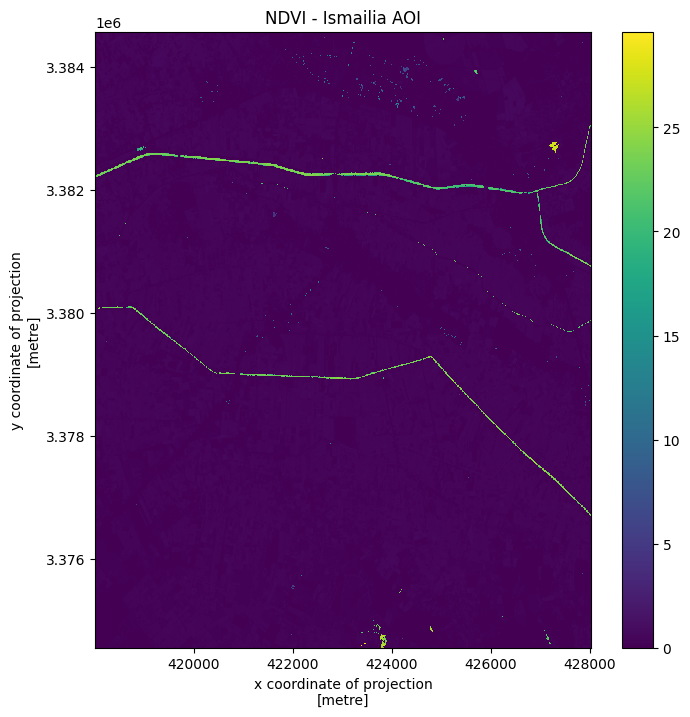

In [15]:
import matplotlib.pyplot as plt

ndvi_aoi.plot(figsize=(8, 8))
plt.title("NDVI - Ismailia AOI")
plt.show()

In [16]:
red_float = red_aoi.astype("float32")
nir_float = nir_aoi.astype("float32")

ndvi_aoi = (nir_float - red_float) / (nir_float + red_float)

print("NDVI fixed ✅")
print("Min:", float(ndvi_aoi.min()))
print("Max:", float(ndvi_aoi.max()))

NDVI fixed ✅
Min: -0.13700033724308014
Max: 0.7083333134651184


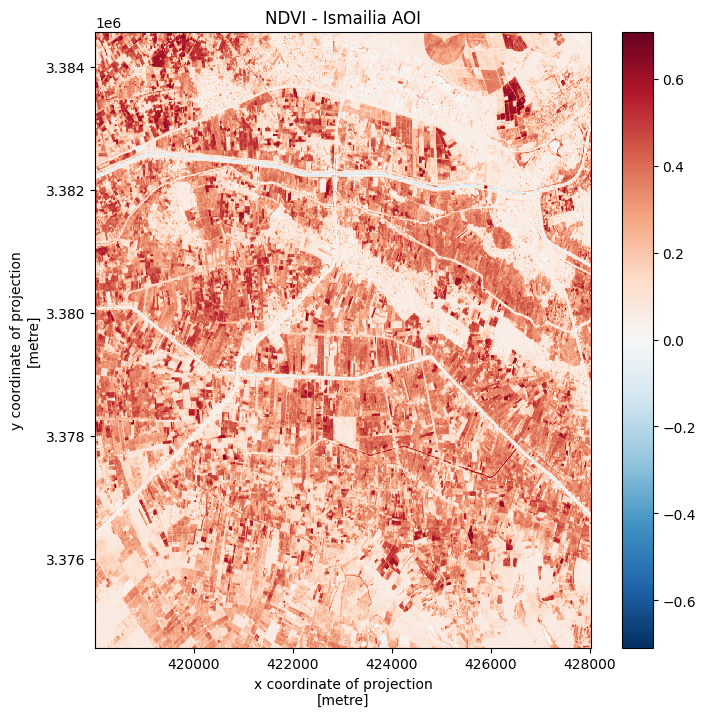

In [17]:
import matplotlib.pyplot as plt

ndvi_aoi.plot(figsize=(8, 8))
plt.title("NDVI - Ismailia AOI")
plt.show()

In [18]:
swir = rioxarray.open_rasterio(
    signed_item.assets["B11"].href
).squeeze()

swir_aoi = swir.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("B11 cropped successfully ✅")
print(swir_aoi.shape)

B11 cropped successfully ✅
(501, 501)


In [19]:
swir_float = swir_aoi.astype("float32")
nir_float = nir_aoi.astype("float32")

ndmi_aoi = (nir_float - swir_float) / (nir_float + swir_float)

print("NDMI calculated successfully ✅")
print(ndmi_aoi.shape)

NDMI calculated successfully ✅
(0, 0)


In [20]:
swir_aoi_10m = swir_aoi.rio.reproject_match(nir_aoi)

print("B11 resampled to B08 grid ✅")
print("B08:", nir_aoi.shape)
print("B11:", swir_aoi_10m.shape)

B11 resampled to B08 grid ✅
B08: (1001, 1001)
B11: (1001, 1001)


In [21]:
nir_float = nir_aoi.astype("float32")
swir_float = swir_aoi_10m.astype("float32")

ndmi_aoi = (nir_float - swir_float) / (nir_float + swir_float)

print("NDMI calculated successfully ✅")
print(ndmi_aoi.shape)
print("Min:", float(ndmi_aoi.min()))
print("Max:", float(ndmi_aoi.max()))

NDMI calculated successfully ✅
(1001, 1001)
Min: -0.44323548674583435
Max: 0.5044284462928772


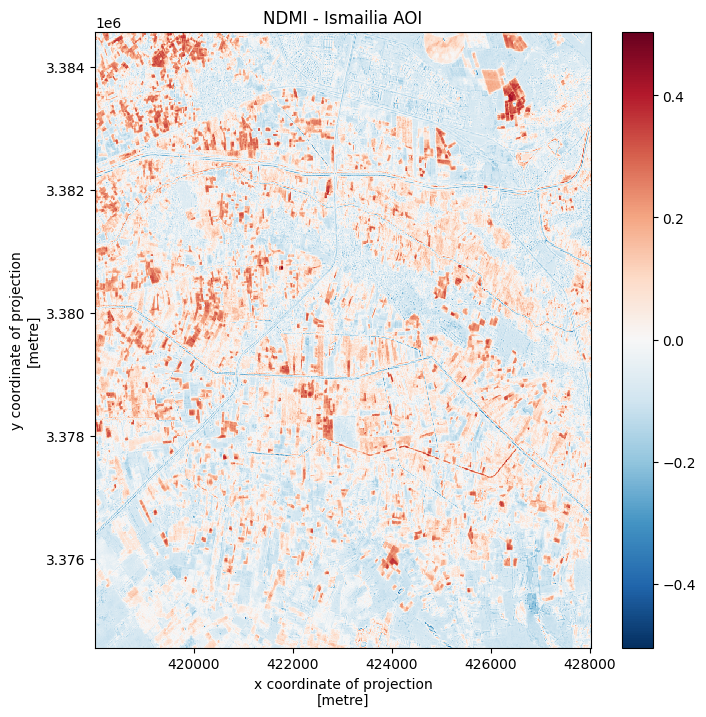

In [22]:
import matplotlib.pyplot as plt

ndmi_aoi.plot(figsize=(8, 8))
plt.title("NDMI - Ismailia AOI")
plt.show()

In [23]:
scl = rioxarray.open_rasterio(
    signed_item.assets["SCL"].href
).squeeze()

scl_aoi = scl.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("SCL cropped successfully ✅")
print(scl_aoi.shape)

SCL cropped successfully ✅
(501, 501)


In [24]:
import numpy as np

classes, counts = np.unique(scl_aoi, return_counts=True)

for cls, count in zip(classes, counts):
    print("Class:", int(cls), "Pixels:", int(count))

Class: 2 Pixels: 752
Class: 4 Pixels: 92874
Class: 5 Pixels: 155548
Class: 6 Pixels: 322
Class: 7 Pixels: 1505


In [25]:
# تحويل SCL لنفس الـ Grid بتاع NDVI
scl_10m = scl_aoi.rio.reproject_match(
    ndvi_aoi,
    resampling=0
)

# نحتفظ بالـ Vegetation فقط
vegetation_mask = scl_10m == 4

print("Vegetation mask created ✅")
print("Vegetation pixels:", int(vegetation_mask.sum()))

Vegetation mask created ✅
Vegetation pixels: 370860


In [26]:
ndvi_vegetation = ndvi_aoi.where(vegetation_mask)

print("Vegetation-only NDVI created ✅")
print("Min:", float(ndvi_vegetation.min(skipna=True)))
print("Max:", float(ndvi_vegetation.max(skipna=True)))

Vegetation-only NDVI created ✅
Min: -0.016655562445521355
Max: 0.7083333134651184


In [27]:
ndmi_vegetation = ndmi_aoi.where(vegetation_mask)

print("Vegetation-only NDMI created ✅")
print("Min:", float(ndmi_vegetation.min(skipna=True)))
print("Max:", float(ndmi_vegetation.max(skipna=True)))

Vegetation-only NDMI created ✅
Min: -0.26686999201774597
Max: 0.5044284462928772


In [28]:
# Normalize NDVI and NDMI داخل الـ AOI
ndvi_min = ndvi_vegetation.min(skipna=True)
ndvi_max = ndvi_vegetation.max(skipna=True)

ndmi_min = ndmi_vegetation.min(skipna=True)
ndmi_max = ndmi_vegetation.max(skipna=True)

ndvi_norm = (ndvi_vegetation - ndvi_min) / (ndvi_max - ndvi_min)
ndmi_norm = (ndmi_vegetation - ndmi_min) / (ndmi_max - ndmi_min)

# Higher value = relatively lower vegetation + lower moisture
stress_indicator = 1 - ((ndvi_norm + ndmi_norm) / 2)

print("Relative stress indicator created ✅")
print(
    "Min:",
    float(stress_indicator.min(skipna=True)),
    "Max:",
    float(stress_indicator.max(skipna=True))
)

Relative stress indicator created ✅
Min: 0.046959890512192404 Max: 0.952473241349469


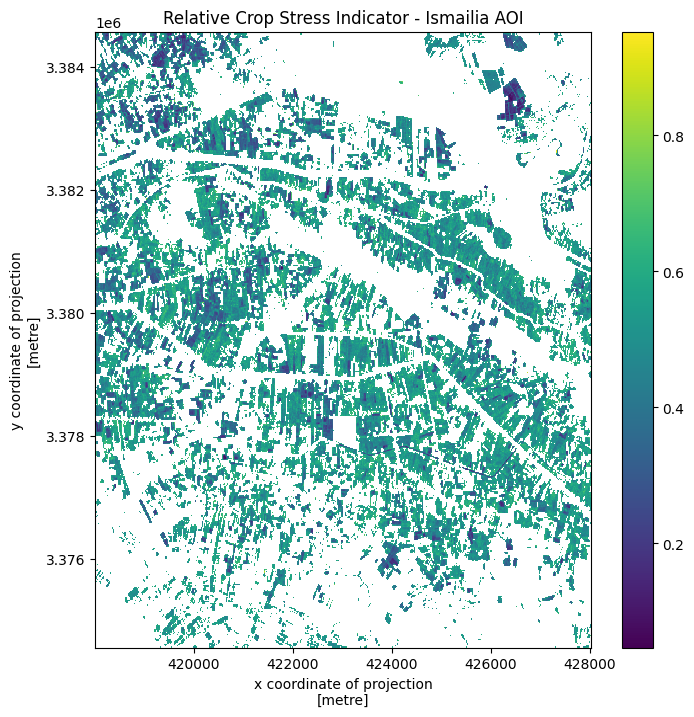

In [29]:
import matplotlib.pyplot as plt

stress_indicator.plot(figsize=(8, 8))
plt.title("Relative Crop Stress Indicator - Ismailia AOI")
plt.show()

In [30]:
import xarray as xr

q33 = stress_indicator.quantile(0.33)
q66 = stress_indicator.quantile(0.66)

priority_map = xr.where(
    stress_indicator <= q33,
    1,
    xr.where(
        stress_indicator <= q66,
        2,
        3
    )
)

print("Priority map created ✅")
print("Low threshold:", float(q33))
print("High threshold:", float(q66))

Priority map created ✅
Low threshold: 0.47098536726168494
High threshold: 0.5541356940866461


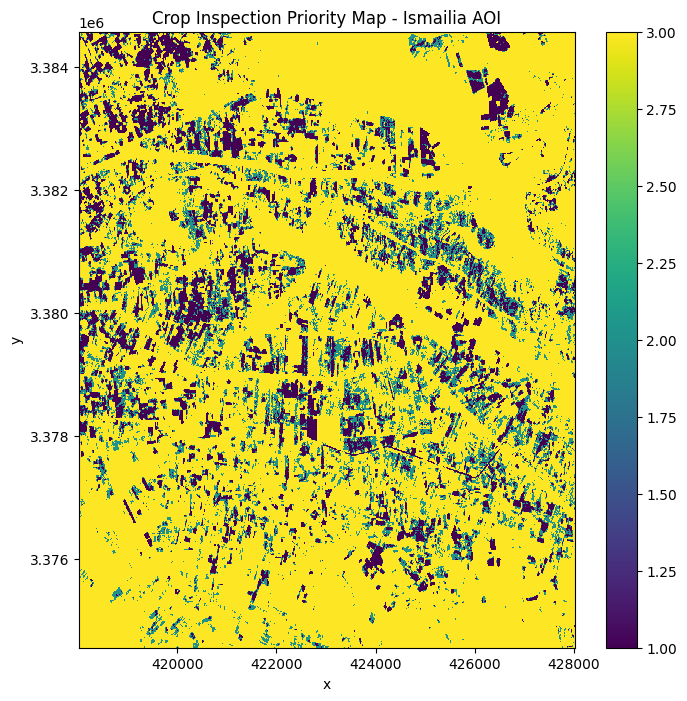

In [31]:
import matplotlib.pyplot as plt

priority_map.plot(figsize=(8, 8))

plt.title("Crop Inspection Priority Map - Ismailia AOI")
plt.show()

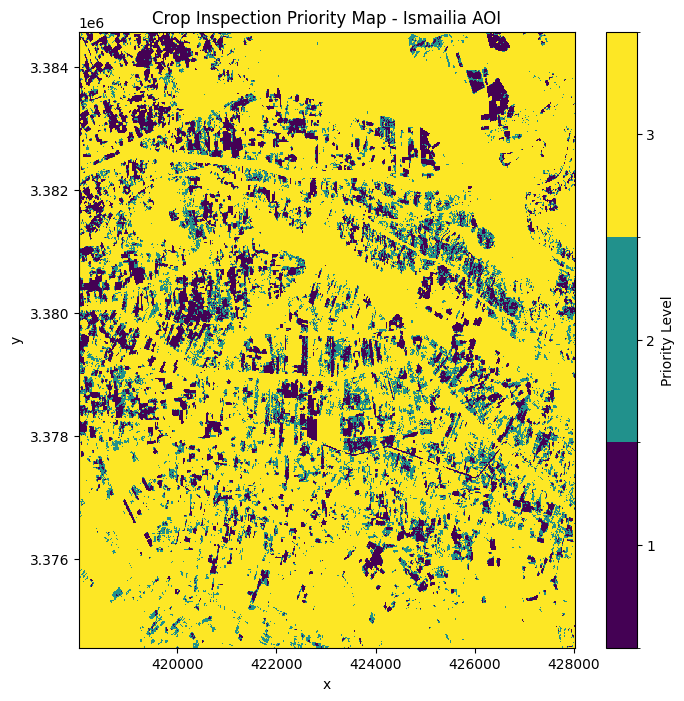

In [32]:
import matplotlib.pyplot as plt

priority_map.plot(
    figsize=(8, 8),
    levels=[0.5, 1.5, 2.5, 3.5],
    cbar_kwargs={
        "ticks": [1, 2, 3],
        "label": "Priority Level"
    }
)

plt.title("Crop Inspection Priority Map - Ismailia AOI")
plt.show()

In [33]:
low_pixels = int((priority_map == 1).sum())
medium_pixels = int((priority_map == 2).sum())
high_pixels = int((priority_map == 3).sum())

# كل Pixel في NDVI حجمه 10m × 10m = 100 m²
pixel_area_m2 = 10 * 10

low_ha = low_pixels * pixel_area_m2 / 10000
medium_ha = medium_pixels * pixel_area_m2 / 10000
high_ha = high_pixels * pixel_area_m2 / 10000

print("Low priority:")
print("Pixels:", low_pixels, "| Area:", round(low_ha, 2), "ha")

print("\nMedium priority:")
print("Pixels:", medium_pixels, "| Area:", round(medium_ha, 2), "ha")

print("\nHigh priority:")
print("Pixels:", high_pixels, "| Area:", round(high_ha, 2), "ha")

Low priority:
Pixels: 122384 | Area: 1223.84 ha

Medium priority:
Pixels: 122383 | Area: 1223.83 ha

High priority:
Pixels: 757234 | Area: 7572.34 ha


In [34]:
priority_map = xr.where(
    stress_indicator.isnull(),
    np.nan,
    xr.where(
        stress_indicator <= q33,
        1,
        xr.where(
            stress_indicator <= q66,
            2,
            3
        )
    )
)

print("Priority map fixed ✅")
print("Valid priority pixels:", int(priority_map.count()))

Priority map fixed ✅
Valid priority pixels: 370860


In [35]:
low_pixels = int((priority_map == 1).sum())
medium_pixels = int((priority_map == 2).sum())
high_pixels = int((priority_map == 3).sum())

pixel_area_m2 = 10 * 10

low_ha = low_pixels * pixel_area_m2 / 10000
medium_ha = medium_pixels * pixel_area_m2 / 10000
high_ha = high_pixels * pixel_area_m2 / 10000

print("Low priority:")
print("Pixels:", low_pixels, "| Area:", round(low_ha, 2), "ha")

print("\nMedium priority:")
print("Pixels:", medium_pixels, "| Area:", round(medium_ha, 2), "ha")

print("\nHigh priority:")
print("Pixels:", high_pixels, "| Area:", round(high_ha, 2), "ha")

print("\nTotal vegetation area:",
      round(low_ha + medium_ha + high_ha, 2), "ha")

Low priority:
Pixels: 122384 | Area: 1223.84 ha

Medium priority:
Pixels: 122383 | Area: 1223.83 ha

High priority:
Pixels: 126093 | Area: 1260.93 ha

Total vegetation area: 3708.6 ha


In [36]:
!pip install -q pystac-client

from pystac_client import Client

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    datetime="2026-08-01/2026-09-16",
    query={
        "s2:mgrs_tile": {"eq": "36RVU"},
        "eo:cloud_cover": {"lt": 20}
    }
)

items = list(search.items())

print("Images found:", len(items))

for item in items:
    print(
        item.datetime.strftime("%Y-%m-%d"),
        "| Cloud:",
        item.properties.get("eo:cloud_cover"),
        "| ID:",
        item.id
    )

Images found: 30
2026-09-16 | Cloud: 0.023583 | ID: S2A_MSIL2A_20260916T083521_R021_T36RVU_20260916T132413
2026-09-16 | Cloud: 0.003562 | ID: S2B_MSIL2A_20260916T081559_R121_T36RVU_20260916T122545
2026-09-14 | Cloud: 0.015458 | ID: S2C_MSIL2A_20260914T082601_R021_T36RVU_20260914T135510
2026-09-13 | Cloud: 0.008559 | ID: S2A_MSIL2A_20260913T082021_R121_T36RVU_20260913T134510
2026-09-11 | Cloud: 0.0 | ID: S2C_MSIL2A_20260911T081601_R121_T36RVU_20260911T134010
2026-09-11 | Cloud: 0.293876 | ID: S2C_MSIL2A_20260911T081601_R121_T36RVU_20260911T120815
2026-09-09 | Cloud: 0.018752 | ID: S2B_MSIL2A_20260909T082559_R021_T36RVU_20260909T122932
2026-09-06 | Cloud: 0.072083 | ID: S2A_MSIL2A_20260906T082751_R021_T36RVU_20260906T135310
2026-09-06 | Cloud: 0.000139 | ID: S2B_MSIL2A_20260906T081559_R121_T36RVU_20260906T121933
2026-09-04 | Cloud: 0.008046 | ID: S2C_MSIL2A_20260904T082601_R021_T36RVU_20260904T135015
2026-09-03 | Cloud: 0.011322 | ID: S2A_MSIL2A_20260903T082601_R121_T36RVU_20260903T13191

In [37]:
from datetime import datetime

target_dates = [
    "2026-08-02",
    "2026-08-12",
    "2026-08-22",
    "2026-09-01",
    "2026-09-11",
    "2026-09-16"
]

selected_items = []

for target in target_dates:
    same_date = [
        item for item in items
        if item.datetime.strftime("%Y-%m-%d") == target
    ]

    if same_date:
        best_item = min(
            same_date,
            key=lambda item: item.properties.get("eo:cloud_cover", 100)
        )
        selected_items.append(best_item)

print("Selected images:", len(selected_items))

for item in selected_items:
    print(
        item.datetime.strftime("%Y-%m-%d"),
        "| Cloud:",
        item.properties.get("eo:cloud_cover"),
        "| ID:",
        item.id
    )

Selected images: 6
2026-08-02 | Cloud: 0.0 | ID: S2C_MSIL2A_20260802T081611_R121_T36RVU_20260802T135020
2026-08-12 | Cloud: 0.000143 | ID: S2C_MSIL2A_20260812T081601_R121_T36RVU_20260812T134614
2026-08-22 | Cloud: 0.0 | ID: S2C_MSIL2A_20260822T081601_R121_T36RVU_20260822T134116
2026-09-01 | Cloud: 9.2e-05 | ID: S2C_MSIL2A_20260901T081601_R121_T36RVU_20260901T134516
2026-09-11 | Cloud: 0.0 | ID: S2C_MSIL2A_20260911T081601_R121_T36RVU_20260911T134010
2026-09-16 | Cloud: 0.003562 | ID: S2B_MSIL2A_20260916T081559_R121_T36RVU_20260916T122545


In [38]:
import numpy as np
import pandas as pd

ndvi_results = []

for item in selected_items:
    signed = planetary_computer.sign(item)

    red = rioxarray.open_rasterio(
        signed.assets["B04"].href
    ).squeeze()

    nir = rioxarray.open_rasterio(
        signed.assets["B08"].href
    ).squeeze()

    # Crop to the same AOI
    red_aoi_temp = red.rio.clip_box(
        minx=x_min,
        miny=y_min,
        maxx=x_max,
        maxy=y_max
    )

    nir_aoi_temp = nir.rio.clip_box(
        minx=x_min,
        miny=y_min,
        maxx=x_max,
        maxy=y_max
    )

    # Convert before subtraction
    red_float = red_aoi_temp.astype("float32")
    nir_float = nir_aoi_temp.astype("float32")

    ndvi_temp = (nir_float - red_float) / (
        nir_float + red_float
    )

    ndvi_mean = float(ndvi_temp.mean(skipna=True))

    ndvi_results.append({
        "date": item.datetime.strftime("%Y-%m-%d"),
        "ndvi_mean": ndvi_mean
    })

ndvi_df = pd.DataFrame(ndvi_results)

print(ndvi_df)

         date  ndvi_mean
0  2026-08-02        NaN
1  2026-08-12        NaN
2  2026-08-22        NaN
3  2026-09-01        NaN
4  2026-09-11        NaN
5  2026-09-16        NaN


In [39]:
test_item = selected_items[0]
signed = planetary_computer.sign(test_item)

red_test = rioxarray.open_rasterio(
    signed.assets["B04"].href
).squeeze()

nir_test = rioxarray.open_rasterio(
    signed.assets["B08"].href
).squeeze()

print("Red CRS:", red_test.rio.crs)
print("Red bounds:", red_test.rio.bounds())

print("AOI:")
print("x:", x_min, "to", x_max)
print("y:", y_min, "to", y_max)

red_test_aoi = red_test.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("Cropped shape:", red_test_aoi.shape)
print("Valid pixels:", int(red_test_aoi.count()))

Red CRS: EPSG:32636
Red bounds: (399960.0, 3290220.0, 509760.0, 3400020.0)
AOI:
x: 418017.9617508978 to 428017.9617508978
y: 3374560.030211411 to 3384560.030211411
Cropped shape: (1001, 1001)
Valid pixels: 1002001


In [40]:
red_float = red_test_aoi.astype("float32")

nir_test_aoi = nir_test.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
).astype("float32")

ndvi_test = (nir_test_aoi - red_float) / (
    nir_test_aoi + red_float
)

print("NDVI valid pixels:", int(ndvi_test.count()))
print("NDVI min:", float(ndvi_test.min(skipna=True)))
print("NDVI max:", float(ndvi_test.max(skipna=True)))
print("NDVI mean:", float(ndvi_test.mean(skipna=True)))

NDVI valid pixels: 0
NDVI min: nan
NDVI max: nan
NDVI mean: nan


In [41]:
print("Red:")
print(red_test_aoi.dtype)
print("Min:", float(red_test_aoi.min()))
print("Max:", float(red_test_aoi.max()))

print("\nNIR:")
print(nir_test_aoi.dtype)
print("Min:", float(nir_test_aoi.min()))
print("Max:", float(nir_test_aoi.max()))

Red:
uint16
Min: 0.0
Max: 0.0

NIR:
float32
Min: 0.0
Max: 0.0


In [42]:
for item in selected_items:
    print(
        item.datetime.strftime("%Y-%m-%d"),
        "| ID:", item.id,
        "| Orbit:", item.properties.get("sat:relative_orbit"),
        "| Platform:", item.properties.get("platform")
    )

2026-08-02 | ID: S2C_MSIL2A_20260802T081611_R121_T36RVU_20260802T135020 | Orbit: 121 | Platform: Sentinel-2C
2026-08-12 | ID: S2C_MSIL2A_20260812T081601_R121_T36RVU_20260812T134614 | Orbit: 121 | Platform: Sentinel-2C
2026-08-22 | ID: S2C_MSIL2A_20260822T081601_R121_T36RVU_20260822T134116 | Orbit: 121 | Platform: Sentinel-2C
2026-09-01 | ID: S2C_MSIL2A_20260901T081601_R121_T36RVU_20260901T134516 | Orbit: 121 | Platform: Sentinel-2C
2026-09-11 | ID: S2C_MSIL2A_20260911T081601_R121_T36RVU_20260911T134010 | Orbit: 121 | Platform: Sentinel-2C
2026-09-16 | ID: S2B_MSIL2A_20260916T081559_R121_T36RVU_20260916T122545 | Orbit: 121 | Platform: Sentinel-2B


In [43]:
test_item = selected_items[0]
signed_test = planetary_computer.sign(test_item)

print("B04 URL exists:", "B04" in signed_test.assets)
print("B08 URL exists:", "B08" in signed_test.assets)

print("B04:", signed_test.assets["B04"].href[:100])
print("B08:", signed_test.assets["B08"].href[:100])

B04 URL exists: True
B08 URL exists: True
B04: https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/36/R/VU/2026/08/02/S2C_MSIL2A_20260802T081
B08: https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/36/R/VU/2026/08/02/S2C_MSIL2A_20260802T081


In [44]:
signed_test = planetary_computer.sign(test_item)

b04_url = signed_test.assets["B04"].href

print("Signed URL:")
print(b04_url[:300])
print("\nHas SAS signature:", "sig=" in b04_url)

Signed URL:
https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/36/R/VU/2026/08/02/S2C_MSIL2A_20260802T081611_N0512_R121_T36RVU_20260802T135020.SAFE/GRANULE/L2A_T36RVU_A009958_20260802T082553/IMG_DATA/R10m/T36RVU_20260802T081611_B04_10m.tif?st=2026-09-19T14%3A34%3A51Z&se=2026-09-20T15%3A19%3A51Z&sp=rl&sv=

Has SAS signature: True


In [45]:
import requests

signed_test = planetary_computer.sign(test_item)
b04_url = signed_test.assets["B04"].href

response = requests.get(b04_url, stream=True)

print("Status Code:", response.status_code)
print("Content-Type:", response.headers.get("Content-Type"))
print("Content-Length:", response.headers.get("Content-Length"))

Status Code: 200
Content-Type: application/octet-stream
Content-Length: 21329163


In [46]:
import rioxarray

signed_test = planetary_computer.sign(test_item)

b04 = rioxarray.open_rasterio(
    signed_test.assets["B04"].href
).squeeze()

print("dtype:", b04.dtype)
print("shape:", b04.shape)
print("min:", float(b04.min()))
print("max:", float(b04.max()))

dtype: uint16
shape: (10980, 10980)
min: 0.0
max: 13363.0


In [47]:
signed_test = planetary_computer.sign(test_item)

red = rioxarray.open_rasterio(
    signed_test.assets["B04"].href
).squeeze()

nir = rioxarray.open_rasterio(
    signed_test.assets["B08"].href
).squeeze()

red_aoi = red.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

nir_aoi = nir.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("Red AOI:")
print("shape:", red_aoi.shape)
print("min:", float(red_aoi.min()))
print("max:", float(red_aoi.max()))

print("\nNIR AOI:")
print("shape:", nir_aoi.shape)
print("min:", float(nir_aoi.min()))
print("max:", float(nir_aoi.max()))

Red AOI:
shape: (1001, 1001)
min: 0.0
max: 0.0

NIR AOI:
shape: (1001, 1001)
min: 0.0
max: 0.0


In [48]:
print("Original bounds:")
print(red.rio.bounds())

print("\nAOI bounds:")
print(red_aoi.rio.bounds())

print("\nAOI transform:")
print(red_aoi.rio.transform())

print("\nCenter pixel:")
print(float(red_aoi.isel(
    y=red_aoi.shape[0] // 2,
    x=red_aoi.shape[1] // 2
)))

Original bounds:
(399960.0, 3290220.0, 509760.0, 3400020.0)

AOI bounds:
(418010.0, 3374560.0, 428020.0, 3384570.0)

AOI transform:
| 10.00, 0.00, 418010.00|
| 0.00,-10.00, 3384570.00|
| 0.00, 0.00, 1.00|

Center pixel:
0.0


In [49]:
from shapely.geometry import Point, shape

center_point = Point(
    32.197409,
    30.545972
)

image_footprint = shape(test_item.geometry)

print("AOI center inside image footprint:",
      image_footprint.contains(center_point))

print("Image bbox:")
print(test_item.bbox)

print("\nAOI center:")
print(center_point)

AOI center inside image footprint: False
Image bbox:
[32.8897452, 29.7414204, 33.1017875, 30.5725482]

AOI center:
POINT (32.197409 30.545972)


In [50]:
from shapely.geometry import box, mapping

# AOI بالـ Longitude / Latitude
aoi = box(
    32.197409 - 0.05,
    30.545972 - 0.05,
    32.197409 + 0.05,
    30.545972 + 0.05
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    datetime="2026-08-02/2026-08-02",
    intersects=mapping(aoi),
    query={"eo:cloud_cover": {"lt": 20}}
)

items_2aug = list(search.items())

print("Images covering AOI:", len(items_2aug))

for item in items_2aug:
    print(
        item.id,
        "| cloud:",
        item.properties.get("eo:cloud_cover")
    )

Images covering AOI: 0


In [51]:
from shapely.geometry import box, mapping

aoi = box(
    32.197409 - 0.05,
    30.545972 - 0.05,
    32.197409 + 0.05,
    30.545972 + 0.05
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    datetime="2026-07-29/2026-08-06",
    intersects=mapping(aoi),
    query={"eo:cloud_cover": {"lt": 20}}
)

items_aoi = list(search.items())

print("Images covering AOI:", len(items_aoi))

for item in items_aoi[:20]:
    print(
        item.id,
        "| date:", item.datetime,
        "| cloud:", item.properties.get("eo:cloud_cover")
    )

Images covering AOI: 2
S2C_MSIL2A_20260805T082601_R021_T36RVU_20260805T135217 | date: 2026-08-05 08:26:01.025000+00:00 | cloud: 0.097398
S2B_MSIL2A_20260731T082559_R021_T36RVU_20260731T123008 | date: 2026-07-31 08:25:59.024000+00:00 | cloud: 0.10769


In [52]:
test_item = items_aoi[0]

print("Selected image:")
print(test_item.id)
print("Date:", test_item.datetime)
print("Cloud:", test_item.properties.get("eo:cloud_cover"))

signed_test = planetary_computer.sign(test_item)

red = rioxarray.open_rasterio(
    signed_test.assets["B04"].href
).squeeze()

nir = rioxarray.open_rasterio(
    signed_test.assets["B08"].href
).squeeze()

red_aoi = red.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

nir_aoi = nir.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("\nRed AOI:")
print("shape:", red_aoi.shape)
print("min:", float(red_aoi.min()))
print("max:", float(red_aoi.max()))

print("\nNIR AOI:")
print("shape:", nir_aoi.shape)
print("min:", float(nir_aoi.min()))
print("max:", float(nir_aoi.max()))

Selected image:
S2C_MSIL2A_20260805T082601_R021_T36RVU_20260805T135217
Date: 2026-08-05 08:26:01.025000+00:00
Cloud: 0.097398

Red AOI:
shape: (1001, 1001)
min: 1227.0
max: 7797.0

NIR AOI:
shape: (1001, 1001)
min: 1278.0
max: 7826.0


In [53]:
red_float = red_aoi.astype("float32")
nir_float = nir_aoi.astype("float32")

ndvi_aoi = (nir_float - red_float) / (nir_float + red_float)

print("NDVI:")
print("min:", float(ndvi_aoi.min()))
print("max:", float(ndvi_aoi.max()))
print("mean:", float(ndvi_aoi.mean()))

NDVI:
min: -0.11770797520875931
max: 0.6865099668502808
mean: 0.249941885471344


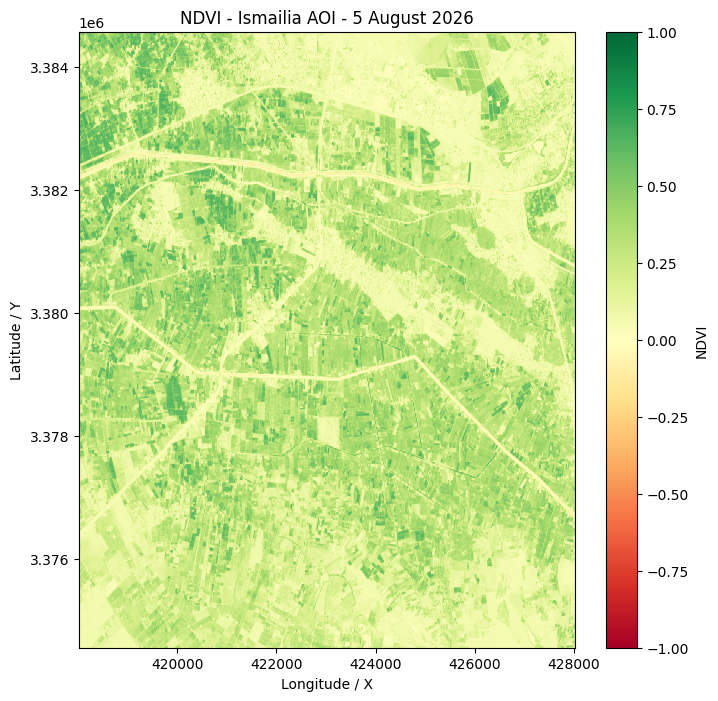

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

ndvi_aoi.plot(
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    cbar_kwargs={"label": "NDVI"}
)

plt.title("NDVI - Ismailia AOI - 5 August 2026")
plt.xlabel("Longitude / X")
plt.ylabel("Latitude / Y")
plt.show()

In [55]:
swir = rioxarray.open_rasterio(
    signed_test.assets["B11"].href
).squeeze()

swir_aoi = swir.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("SWIR B11:")
print("shape:", swir_aoi.shape)
print("min:", float(swir_aoi.min()))
print("max:", float(swir_aoi.max()))

SWIR B11:
shape: (501, 501)
min: 1366.0
max: 7850.0


In [56]:
# تحويل B11 من 20m إلى نفس شبكة B08 (10m)
swir_aoi_10m = swir_aoi.rio.reproject_match(
    nir_aoi
)

print("B11 after resampling:")
print("shape:", swir_aoi_10m.shape)
print("min:", float(swir_aoi_10m.min()))
print("max:", float(swir_aoi_10m.max()))

B11 after resampling:
shape: (1001, 1001)
min: 1366.0
max: 7850.0


In [ ]:
nir_float = nir_aoi.astype("float32")
swir_float = swir_aoi_10m.astype("float32")

ndmi_aoi = (nir_float - swir_float) / (nir_float + swir_float)

print("NDMI:")
print("min:", float(ndmi_aoi.min()))
print("max:", float(ndmi_aoi.max()))
print("mean:", float(ndmi_aoi.mean()))

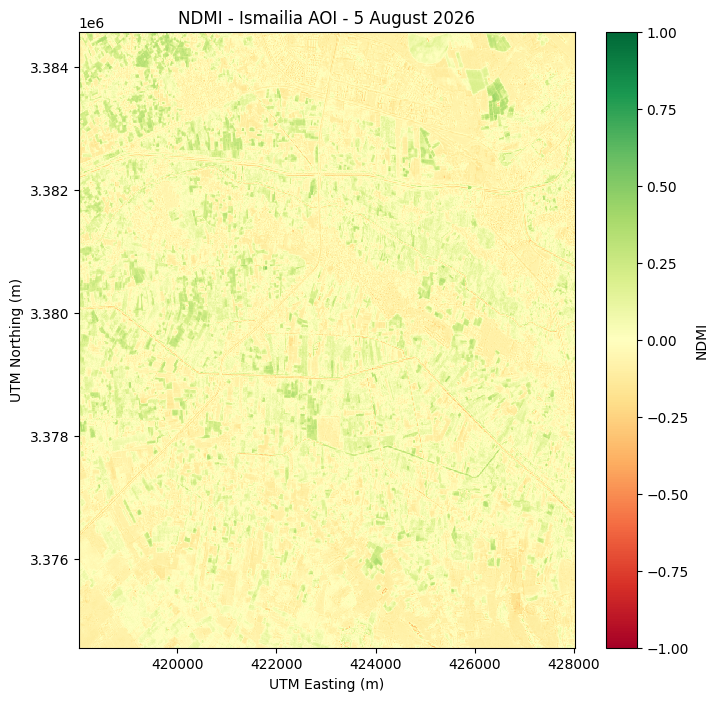

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

ndmi_aoi.plot(
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    cbar_kwargs={"label": "NDMI"}
)

plt.title("NDMI - Ismailia AOI - 5 August 2026")
plt.xlabel("UTM Easting (m)")
plt.ylabel("UTM Northing (m)")

plt.show()

In [58]:
scl = rioxarray.open_rasterio(
    signed_test.assets["SCL"].href
).squeeze()

scl_aoi = scl.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("SCL:")
print("shape:", scl_aoi.shape)
print("unique classes:", sorted(scl_aoi.values.flatten()[~__import__("numpy").isnan(scl_aoi.values.flatten())].astype(int).tolist())[:20])

SCL:
shape: (501, 501)
unique classes: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


In [59]:
import numpy as np

classes, counts = np.unique(
    scl_aoi.values,
    return_counts=True
)

print("SCL classes:")
for cls, count in zip(classes.astype(int), counts):
    print(f"Class {cls}: {count} pixels")

SCL classes:
Class 2: 70 pixels
Class 4: 100294 pixels
Class 5: 149439 pixels
Class 6: 253 pixels
Class 7: 945 pixels


In [60]:
# تحويل SCL إلى شبكة NDVI ذات الدقة 10m
scl_10m = scl_aoi.rio.reproject_match(
    ndvi_aoi,
    resampling=0
)

# Class 4 = Vegetation
vegetation_mask = scl_10m == 4

print("Vegetation pixels:", int(vegetation_mask.sum()))
print("Total pixels:", vegetation_mask.size)

Vegetation pixels: 400457
Total pixels: 1002001


In [61]:
# نخلي المناطق غير النباتية = NaN
ndvi_vegetation = ndvi_aoi.where(vegetation_mask)
ndmi_vegetation = ndmi_aoi.where(vegetation_mask)

print("NDVI over vegetation:")
print("min:", float(ndvi_vegetation.min(skipna=True)))
print("max:", float(ndvi_vegetation.max(skipna=True)))
print("mean:", float(ndvi_vegetation.mean(skipna=True)))

print("\nNDMI over vegetation:")
print("min:", float(ndmi_vegetation.min(skipna=True)))
print("max:", float(ndmi_vegetation.max(skipna=True)))
print("mean:", float(ndmi_vegetation.mean(skipna=True)))

NDVI over vegetation:
min: 0.008666479960083961
max: 0.6865099668502808
mean: 0.39767029881477356

NDMI over vegetation:
min: -0.32965150475502014
max: 0.5044284462928772
mean: 0.05805901810526848


In [62]:
ndvi_min = ndvi_vegetation.min(skipna=True)
ndvi_max = ndvi_vegetation.max(skipna=True)

ndmi_min = ndmi_vegetation.min(skipna=True)
ndmi_max = ndmi_vegetation.max(skipna=True)

ndvi_norm = (
    (ndvi_vegetation - ndvi_min)
    / (ndvi_max - ndvi_min)
)

ndmi_norm = (
    (ndmi_vegetation - ndmi_min)
    / (ndmi_max - ndmi_min)
)

print("NDVI normalized:")
print(
    "min:", float(ndvi_norm.min(skipna=True)),
    "max:", float(ndvi_norm.max(skipna=True))
)

print("\nNDMI normalized:")
print(
    "min:", float(ndmi_norm.min(skipna=True)),
    "max:", float(ndmi_norm.max(skipna=True))
)

NDVI normalized:
min: 0.0 max: 1.0

NDMI normalized:
min: 0.0 max: 1.0


In [63]:
stress_indicator = 1 - (
    (ndvi_norm + ndmi_norm) / 2
)

print("Stress Indicator:")
print("min:", float(stress_indicator.min(skipna=True)))
print("max:", float(stress_indicator.max(skipna=True)))
print("mean:", float(stress_indicator.mean(skipna=True)))

Stress Indicator:
min: 0.06149868243465573
max: 0.8840389647843977
mean: 0.48063905565389775


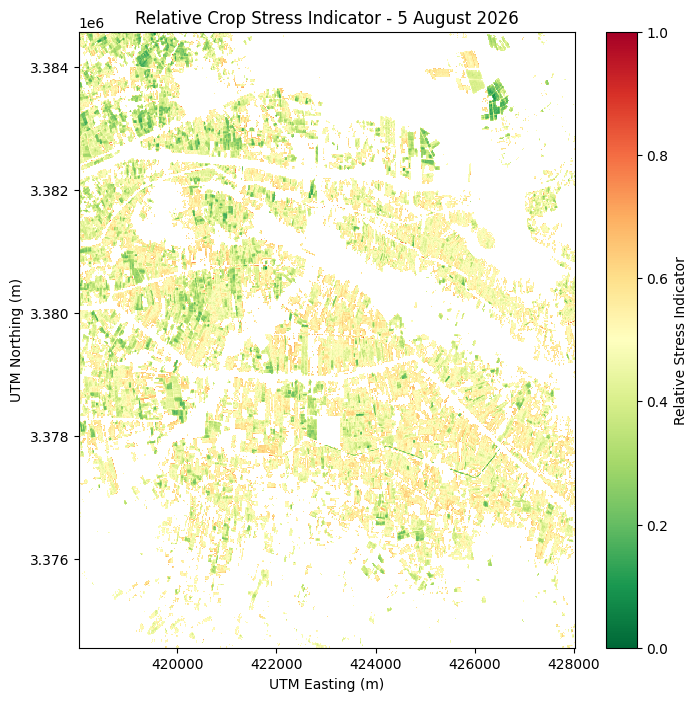

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

stress_indicator.plot(
    cmap="RdYlGn_r",
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "Relative Stress Indicator"}
)

plt.title("Relative Crop Stress Indicator - 5 August 2026")
plt.xlabel("UTM Easting (m)")
plt.ylabel("UTM Northing (m)")

plt.show()

In [65]:
import xarray as xr

q33 = stress_indicator.quantile(0.33)
q66 = stress_indicator.quantile(0.66)

priority_map = xr.where(
    stress_indicator.isnull(),
    np.nan,
    xr.where(
        stress_indicator <= q33,
        1,
        xr.where(
            stress_indicator <= q66,
            2,
            3
        )
    )
)

print("Low threshold:", float(q33))
print("High threshold:", float(q66))

print("\nPriority pixels:")
print("Low:", int((priority_map == 1).sum()))
print("Medium:", int((priority_map == 2).sum()))
print("High:", int((priority_map == 3).sum()))

Low threshold: 0.452576201514545
High threshold: 0.5293856132657074

Priority pixels:
Low: 132151
Medium: 132150
High: 136156


In [66]:
pixel_area_ha = 0.01

low_pixels = int((priority_map == 1).sum())
medium_pixels = int((priority_map == 2).sum())
high_pixels = int((priority_map == 3).sum())

low_area = low_pixels * pixel_area_ha
medium_area = medium_pixels * pixel_area_ha
high_area = high_pixels * pixel_area_ha

total_area = low_area + medium_area + high_area

print("Priority Areas:")
print(f"Low Priority:    {low_area:.2f} ha")
print(f"Medium Priority: {medium_area:.2f} ha")
print(f"High Priority:   {high_area:.2f} ha")
print(f"Total Vegetation: {total_area:.2f} ha")

Priority Areas:
Low Priority:    1321.51 ha
Medium Priority: 1321.50 ha
High Priority:   1361.56 ha
Total Vegetation: 4004.57 ha


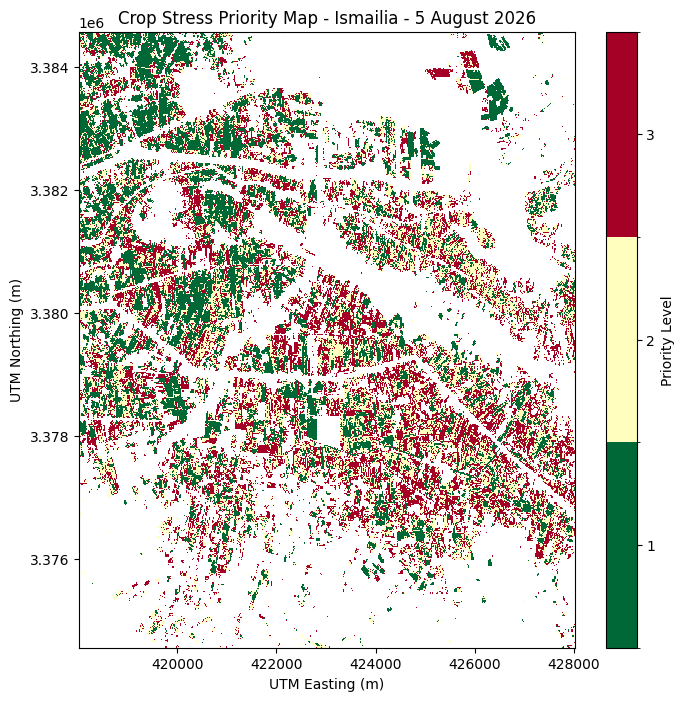

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

priority_map.plot(
    levels=[0.5, 1.5, 2.5, 3.5],
    cmap="RdYlGn_r",
    cbar_kwargs={
        "ticks": [1, 2, 3],
        "label": "Priority Level"
    }
)

plt.title("Crop Stress Priority Map - Ismailia - 5 August 2026")
plt.xlabel("UTM Easting (m)")
plt.ylabel("UTM Northing (m)")

plt.show()

In [68]:
from pystac_client import Client
import planetary_computer

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    intersects={
        "type": "Point",
        "coordinates": [32.197409, 30.545972]
    },
    datetime="2026-08-20/2026-08-25",
    query={
        "eo:cloud_cover": {"lt": 20}
    }
)

items_time = list(search.get_items())

print("Number of images:", len(items_time))

for item in items_time:
    print(
        item.id,
        "|",
        item.datetime,
        "| Cloud:",
        item.properties.get("eo:cloud_cover")
    )

Number of images: 2
S2C_MSIL2A_20260825T082601_R021_T36RVU_20260825T135112 | 2026-08-25 08:26:01.025000+00:00 | Cloud: 0.087014
S2B_MSIL2A_20260820T082559_R021_T36RVU_20260820T123007 | 2026-08-20 08:25:59.024000+00:00 | Cloud: 0.06992


/usr/local/lib/python3.13/dist-packages/pystac_client/item_search.py:925: FutureWarning: get_items() is deprecated, use items() instead
  warnings.warn(


In [69]:
test_item_2 = items_time[0]

print("ID:", test_item_2.id)
print("Date:", test_item_2.datetime)
print("Cloud:", test_item_2.properties.get("eo:cloud_cover"))
print("BBox:", test_item_2.bbox)

ID: S2C_MSIL2A_20260825T082601_R021_T36RVU_20260825T135112
Date: 2026-08-25 08:26:01.025000+00:00
Cloud: 0.087014
BBox: [31.9550611, 29.7381604, 33.1019523, 30.73303]


In [70]:
signed_item_2 = planetary_computer.sign(test_item_2)

red_2 = rioxarray.open_rasterio(
    signed_item_2.assets["B04"].href
).squeeze()

nir_2 = rioxarray.open_rasterio(
    signed_item_2.assets["B08"].href
).squeeze()

red_aoi_2 = red_2.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

nir_aoi_2 = nir_2.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("Red shape:", red_aoi_2.shape)
print("NIR shape:", nir_aoi_2.shape)

print("Red min/max:", red_aoi_2.min().item(), red_aoi_2.max().item())
print("NIR min/max:", nir_aoi_2.min().item(), nir_aoi_2.max().item())

Red shape: (1001, 1001)
NIR shape: (1001, 1001)
Red min/max: 1063 7738
NIR min/max: 1187 7978


In [71]:
red_float_2 = red_aoi_2.astype("float32")
nir_float_2 = nir_aoi_2.astype("float32")

ndvi_aoi_2 = (
    (nir_float_2 - red_float_2)
    / (nir_float_2 + red_float_2)
)

print("NDVI min:", ndvi_aoi_2.min().item())
print("NDVI max:", ndvi_aoi_2.max().item())
print("NDVI mean:", ndvi_aoi_2.mean().item())

NDVI min: -0.13038092851638794
NDVI max: 0.6866932511329651
NDVI mean: 0.25865480303764343


In [72]:
ndvi_change = ndvi_aoi_2 - ndvi_aoi

print("Change min:", ndvi_change.min().item())
print("Change max:", ndvi_change.max().item())
print("Change mean:", ndvi_change.mean().item())

Change min: -0.68675696849823
Change max: 0.44585859775543213
Change mean: 0.008706005290150642


In [73]:
import pystac
import planetary_computer
import rioxarray

item_url_2 = (
    "https://planetarycomputer.microsoft.com/api/stac/v1/collections/"
    "sentinel-2-l2a/items/"
    "S2C_MSIL2A_20260825T082601_R021_T36RVU_20260825T135112"
)

# Get a fresh copy of the STAC item
fresh_item_2 = pystac.Item.from_file(item_url_2)

# Create fresh signed asset URLs
fresh_signed_item_2 = planetary_computer.sign(fresh_item_2)

# Open SCL using the fresh signed URL
scl_2 = rioxarray.open_rasterio(
    fresh_signed_item_2.assets["SCL"].href
).squeeze()

# Clip to our AOI
scl_aoi_2 = scl_2.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("SCL shape:", scl_aoi_2.shape)
print("SCL min:", scl_aoi_2.min().item())
print("SCL max:", scl_aoi_2.max().item())

SCL shape: (501, 501)
SCL min: 2
SCL max: 7


In [74]:
scl_10m_2 = scl_aoi_2.rio.reproject_match(
    ndvi_aoi_2,
    resampling=0
)

vegetation_mask_2 = scl_10m_2 == 4

print("SCL 10m shape:", scl_10m_2.shape)
print("Vegetation pixels:", vegetation_mask_2.sum().item())
print("Total pixels:", vegetation_mask_2.size)

SCL 10m shape: (1001, 1001)
Vegetation pixels: 424491
Total pixels: 1002001


In [75]:
common_vegetation_mask = (
    vegetation_mask & vegetation_mask_2
)

print(
    "Common vegetation pixels:",
    common_vegetation_mask.sum().item()
)

print(
    "Common vegetation percentage:",
    (
        common_vegetation_mask.sum().item()
        / common_vegetation_mask.size
    ) * 100
)

Common vegetation pixels: 366429
Common vegetation percentage: 36.569723982311395


In [76]:
ndvi_5_common = ndvi_aoi.where(common_vegetation_mask)
ndvi_25_common = ndvi_aoi_2.where(common_vegetation_mask)

ndvi_change_common = ndvi_25_common - ndvi_5_common

print("Common NDVI - 5 Aug")
print("Min:", ndvi_5_common.min(skipna=True).item())
print("Max:", ndvi_5_common.max(skipna=True).item())
print("Mean:", ndvi_5_common.mean(skipna=True).item())

print("\nCommon NDVI - 25 Aug")
print("Min:", ndvi_25_common.min(skipna=True).item())
print("Max:", ndvi_25_common.max(skipna=True).item())
print("Mean:", ndvi_25_common.mean(skipna=True).item())

print("\nCommon NDVI Change")
print("Min:", ndvi_change_common.min(skipna=True).item())
print("Max:", ndvi_change_common.max(skipna=True).item())
print("Mean:", ndvi_change_common.mean(skipna=True).item())

Common NDVI - 5 Aug
Min: 0.008666479960083961
Max: 0.6865099668502808
Mean: 0.39937877655029297

Common NDVI - 25 Aug
Min: 0.07298814505338669
Max: 0.6866932511329651
Mean: 0.4151226580142975

Common NDVI Change
Min: -0.4501636028289795
Max: 0.4405839145183563
Mean: 0.015739653259515762


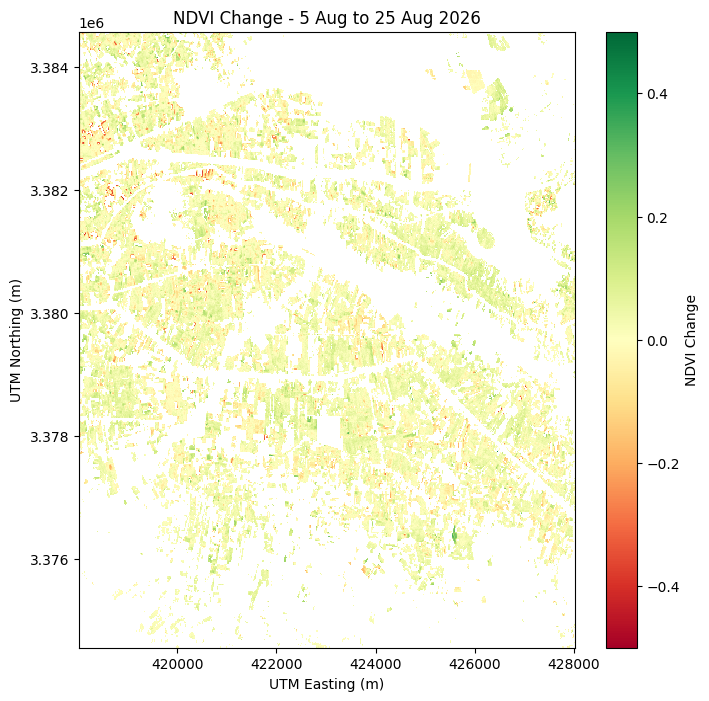

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

ndvi_change_common.plot(
    cmap="RdYlGn",
    vmin=-0.5,
    vmax=0.5,
    cbar_kwargs={
        "label": "NDVI Change"
    }
)

plt.title("NDVI Change - 5 Aug to 25 Aug 2026")
plt.xlabel("UTM Easting (m)")
plt.ylabel("UTM Northing (m)")

plt.show()

In [78]:
# Open B11 using the fresh signed item
swir_2 = rioxarray.open_rasterio(
    fresh_signed_item_2.assets["B11"].href
).squeeze()

# Clip B11 to our AOI
swir_aoi_2 = swir_2.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("B11 shape:", swir_aoi_2.shape)
print("B11 min:", swir_aoi_2.min().item())
print("B11 max:", swir_aoi_2.max().item())

B11 shape: (501, 501)
B11 min: 1249
B11 max: 8057


In [79]:
swir_aoi_2_10m = swir_aoi_2.rio.reproject_match(
    nir_aoi_2
)

print("B11 10m shape:", swir_aoi_2_10m.shape)
print("B11 10m min:", swir_aoi_2_10m.min().item())
print("B11 10m max:", swir_aoi_2_10m.max().item())

B11 10m shape: (1001, 1001)
B11 10m min: 1249
B11 10m max: 8057


In [80]:
# Open B8A using the fresh signed item
nir8a_2 = rioxarray.open_rasterio(
    fresh_signed_item_2.assets["B8A"].href
).squeeze()

# Clip B8A to our AOI
nir8a_aoi_2 = nir8a_2.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("B8A shape:", nir8a_aoi_2.shape)
print("B8A min:", nir8a_aoi_2.min().item())
print("B8A max:", nir8a_aoi_2.max().item())

B8A shape: (501, 501)
B8A min: 1105
B8A max: 7779


In [81]:
b8a_float_2 = nir8a_aoi_2.astype("float32")
b11_float_2 = swir_aoi_2.astype("float32")

ndmi_aoi_2 = (
    (b8a_float_2 - b11_float_2)
    / (b8a_float_2 + b11_float_2)
)

print("NDMI min:", ndmi_aoi_2.min().item())
print("NDMI max:", ndmi_aoi_2.max().item())
print("NDMI mean:", ndmi_aoi_2.mean().item())

NDMI min: -0.21839384734630585
NDMI max: 0.45612528920173645
NDMI mean: 0.032505713403224945


In [82]:
# Fresh STAC item for 5 August
item_url_5 = (
    "https://planetarycomputer.microsoft.com/api/stac/v1/collections/"
    "sentinel-2-l2a/items/"
    "S2C_MSIL2A_20260805T082601_R021_T36RVU_20260805T135217"
)

fresh_item_5 = pystac.Item.from_file(item_url_5)

# Fresh signed URLs
fresh_signed_item_5 = planetary_computer.sign(fresh_item_5)

# Open B8A
nir8a_5 = rioxarray.open_rasterio(
    fresh_signed_item_5.assets["B8A"].href
).squeeze()

# Clip to the same AOI
nir8a_aoi_5 = nir8a_5.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("B8A shape:", nir8a_aoi_5.shape)
print("B8A min:", nir8a_aoi_5.min().item())
print("B8A max:", nir8a_aoi_5.max().item())

B8A shape: (501, 501)
B8A min: 1309
B8A max: 7562


In [83]:
# Open B11 for 5 August
swir_5 = rioxarray.open_rasterio(
    fresh_signed_item_5.assets["B11"].href
).squeeze()

# Clip to the same AOI
swir_aoi_5 = swir_5.rio.clip_box(
    minx=x_min,
    miny=y_min,
    maxx=x_max,
    maxy=y_max
)

print("B11 shape:", swir_aoi_5.shape)
print("B11 min:", swir_aoi_5.min().item())
print("B11 max:", swir_aoi_5.max().item())

B11 shape: (501, 501)
B11 min: 1366
B11 max: 7850


In [84]:
b8a_float_5 = nir8a_aoi_5.astype("float32")
b11_float_5 = swir_aoi_5.astype("float32")

ndmi_aoi_5 = (
    (b8a_float_5 - b11_float_5)
    / (b8a_float_5 + b11_float_5)
)

print("NDMI 5 Aug")
print("Min:", ndmi_aoi_5.min().item())
print("Max:", ndmi_aoi_5.max().item())
print("Mean:", ndmi_aoi_5.mean().item())

NDMI 5 Aug
Min: -0.2630842924118042
Max: 0.42380136251449585
Mean: 0.03199615702033043


In [85]:
from rasterio.enums import Resampling

# Convert Boolean masks to uint8
vegetation_mask_5_uint8 = vegetation_mask.astype("uint8")
vegetation_mask_25_uint8 = vegetation_mask_2.astype("uint8")

# Reproject both masks to the 20m NDMI grid
vegetation_mask_5_20m = vegetation_mask_5_uint8.rio.reproject_match(
    ndmi_aoi_5,
    resampling=Resampling.nearest
)

vegetation_mask_25_20m = vegetation_mask_25_uint8.rio.reproject_match(
    ndmi_aoi_2,
    resampling=Resampling.nearest
)

# Common vegetation pixels
common_vegetation_mask_20m = (
    (vegetation_mask_5_20m == 1) &
    (vegetation_mask_25_20m == 1)
)

print(
    "Common vegetation pixels (20m):",
    common_vegetation_mask_20m.sum().item()
)

print(
    "Total pixels (20m):",
    common_vegetation_mask_20m.size
)

print(
    "Common vegetation percentage:",
    common_vegetation_mask_20m.sum().item()
    / common_vegetation_mask_20m.size * 100
)

Common vegetation pixels (20m): 91773
Total pixels (20m): 251001
Common vegetation percentage: 36.5628025386353


In [86]:
ndmi_5_common = ndmi_aoi_5.where(
    common_vegetation_mask_20m
)

ndmi_25_common = ndmi_aoi_2.where(
    common_vegetation_mask_20m
)

ndmi_change_common = (
    ndmi_25_common - ndmi_5_common
)

print("Common NDMI - 5 Aug")
print(
    "Min:",
    ndmi_5_common.min(skipna=True).item()
)
print(
    "Max:",
    ndmi_5_common.max(skipna=True).item()
)
print(
    "Mean:",
    ndmi_5_common.mean(skipna=True).item()
)

print("\nCommon NDMI - 25 Aug")
print(
    "Min:",
    ndmi_25_common.min(skipna=True).item()
)
print(
    "Max:",
    ndmi_25_common.max(skipna=True).item()
)
print(
    "Mean:",
    ndmi_25_common.mean(skipna=True).item()
)

print("\nCommon NDMI Change")
print(
    "Min:",
    ndmi_change_common.min(skipna=True).item()
)
print(
    "Max:",
    ndmi_change_common.max(skipna=True).item()
)
print(
    "Mean:",
    ndmi_change_common.mean(skipna=True).item()
)

Common NDMI - 5 Aug
Min: -0.07027564197778702
Max: 0.42380136251449585
Mean: 0.1296132504940033

Common NDMI - 25 Aug
Min: -0.06605640798807144
Max: 0.45612528920173645
Mean: 0.1352534145116806

Common NDMI Change
Min: -0.3648131787776947
Max: 0.3036729693412781
Mean: 0.0056391507387161255


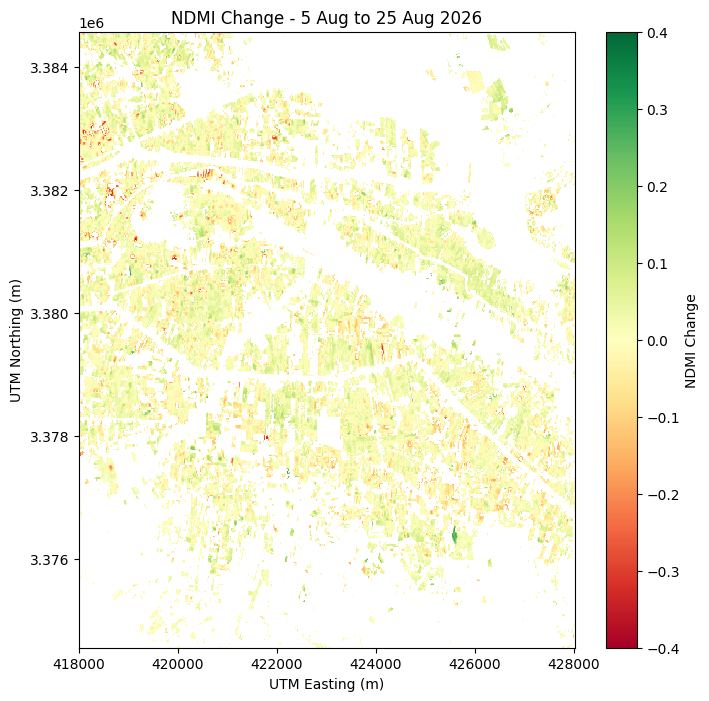

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

ndmi_change_common.plot(
    cmap="RdYlGn",
    vmin=-0.4,
    vmax=0.4,
    cbar_kwargs={
        "label": "NDMI Change"
    }
)

plt.title("NDMI Change - 5 Aug to 25 Aug 2026")
plt.xlabel("UTM Easting (m)")
plt.ylabel("UTM Northing (m)")

plt.show()

In [88]:
# Pixels where BOTH vegetation indicators decreased
potential_stress_mask = (
    (ndvi_change_common < 0) &
    (ndmi_change_common < 0)
)

stress_pixels = potential_stress_mask.sum().item()
total_common_pixels = common_vegetation_mask.sum().item()

print("Potential stress pixels:", stress_pixels)
print("Total common vegetation pixels:", total_common_pixels)

print(
    "Potential stress percentage:",
    stress_pixels / total_common_pixels * 100
)

Potential stress pixels: 0
Total common vegetation pixels: 366429
Potential stress percentage: 0.0


In [89]:
from rasterio.enums import Resampling

# Convert NDVI change from 10m grid to the 20m NDMI grid
ndvi_change_20m = ndvi_change_common.rio.reproject_match(
    ndmi_change_common,
    resampling=Resampling.average
)

print("NDVI Change 20m shape:", ndvi_change_20m.shape)
print("NDMI Change shape:", ndmi_change_common.shape)

NDVI Change 20m shape: (501, 501)
NDMI Change shape: (501, 501)


In [90]:
potential_stress_mask_20m = (
    (ndvi_change_20m < 0) &
    (ndmi_change_common < 0) &
    common_vegetation_mask_20m
)

stress_pixels = potential_stress_mask_20m.sum().item()
common_pixels = common_vegetation_mask_20m.sum().item()

print("Potential stress pixels:", stress_pixels)
print("Common vegetation pixels:", common_pixels)

print(
    "Potential stress percentage:",
    stress_pixels / common_pixels * 100
)

Potential stress pixels: 26407
Common vegetation pixels: 91773
Potential stress percentage: 28.77425822409641


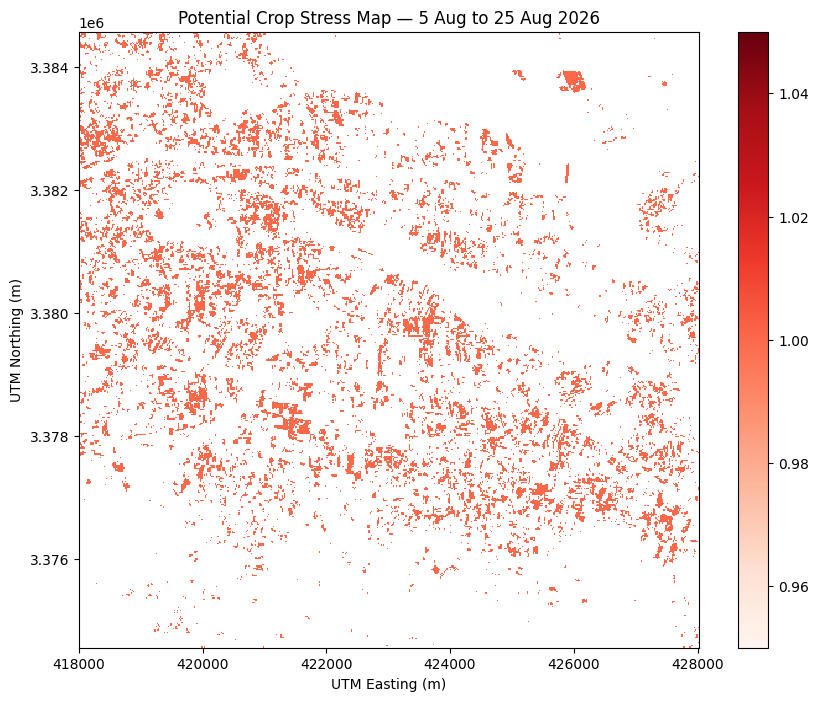

In [91]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

stress_map = xr.where(
    potential_stress_mask_20m,
    1,
    np.nan
)

plt.figure(figsize=(10, 8))

stress_map.plot(
    cmap="Reds",
    add_colorbar=True
)

plt.title("Potential Crop Stress Map — 5 Aug to 25 Aug 2026")
plt.xlabel("UTM Easting (m)")
plt.ylabel("UTM Northing (m)")

plt.show()

In [92]:
# مقدار الانخفاض فقط
ndvi_drop = -ndvi_change_20m.where(
    common_vegetation_mask_20m
)

ndmi_drop = -ndmi_change_common.where(
    common_vegetation_mask_20m
)

# نحتفظ فقط بالمناطق التي انخفض فيها المؤشران معًا
stress_score = (
    ndvi_drop.clip(min=0) +
    ndmi_drop.clip(min=0)
)

# نحتفظ فقط بالـ Potential Stress pixels
stress_score = stress_score.where(
    potential_stress_mask_20m
)

print("Stress Score min:", stress_score.min().item())
print("Stress Score max:", stress_score.max().item())
print("Stress Score mean:", stress_score.mean().item())

Stress Score min: 0.00047390908002853394
Stress Score max: 0.6870478391647339
Stress Score mean: 0.08629559725522995


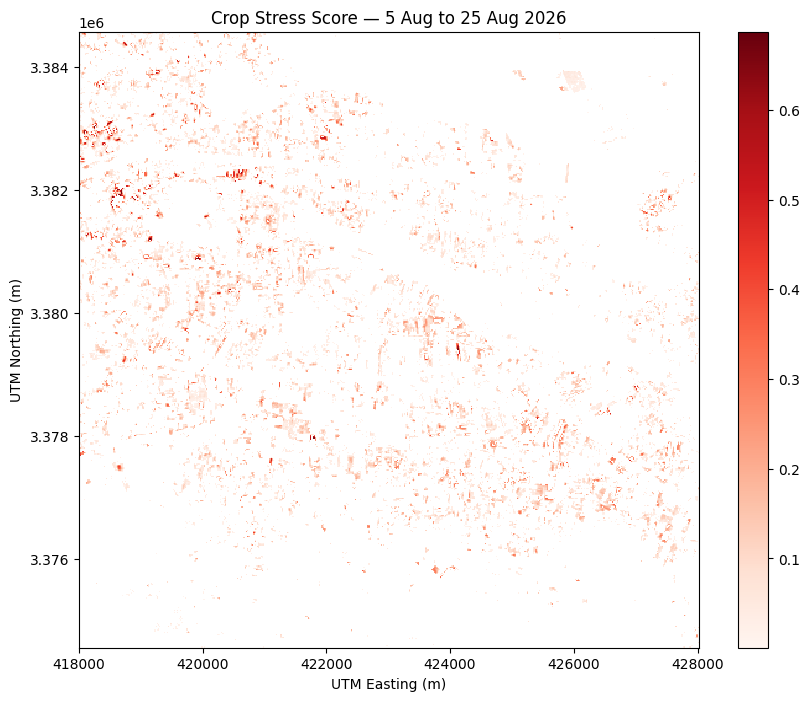

In [93]:
plt.figure(figsize=(10, 8))

stress_score.plot(
    cmap="Reds",
    add_colorbar=True
)

plt.title("Crop Stress Score — 5 Aug to 25 Aug 2026")
plt.xlabel("UTM Easting (m)")
plt.ylabel("UTM Northing (m)")

plt.show()

In [94]:
# نجيب الـ Stress Score values فقط
score_values = stress_score.values
score_values = score_values[~np.isnan(score_values)]

percentiles = np.percentile(
    score_values,
    [50, 75, 90, 95]
)

print("50th percentile:", percentiles[0])
print("75th percentile:", percentiles[1])
print("90th percentile:", percentiles[2])
print("95th percentile:", percentiles[3])

50th percentile: 0.0631106048822403
75th percentile: 0.11306937411427498
90th percentile: 0.18116428852081315
95th percentile: 0.235006396472454


In [95]:
priority_map = xr.full_like(
    stress_score,
    np.nan,
    dtype="float32"
)

# Medium Priority
priority_map = priority_map.where(
    ~(stress_score >= 0.11306937411427498),
    1
)

# High Priority
priority_map = priority_map.where(
    ~(stress_score >= 0.18116428852081315),
    2
)

print("Priority 1 pixels:",
      (priority_map == 1).sum().item())

print("Priority 2 pixels:",
      (priority_map == 2).sum().item())

Priority 1 pixels: 3961
Priority 2 pixels: 2641


In [96]:
priority_map = xr.full_like(
    stress_score,
    np.nan,
    dtype="float32"
)

# Lower Priority
priority_map = xr.where(
    stress_score < 0.11306937411427498,
    0,
    priority_map
)

# Medium Priority
priority_map = xr.where(
    (stress_score >= 0.11306937411427498) &
    (stress_score < 0.18116428852081315),
    1,
    priority_map
)

# High Priority
priority_map = xr.where(
    stress_score >= 0.18116428852081315,
    2,
    priority_map
)

print("Lower Priority:",
      (priority_map == 0).sum().item())

print("Medium Priority:",
      (priority_map == 1).sum().item())

print("High Priority:",
      (priority_map == 2).sum().item())

print("Total:",
      (~np.isnan(priority_map.values)).sum())

Lower Priority: 19805
Medium Priority: 3961
High Priority: 2641
Total: 26407


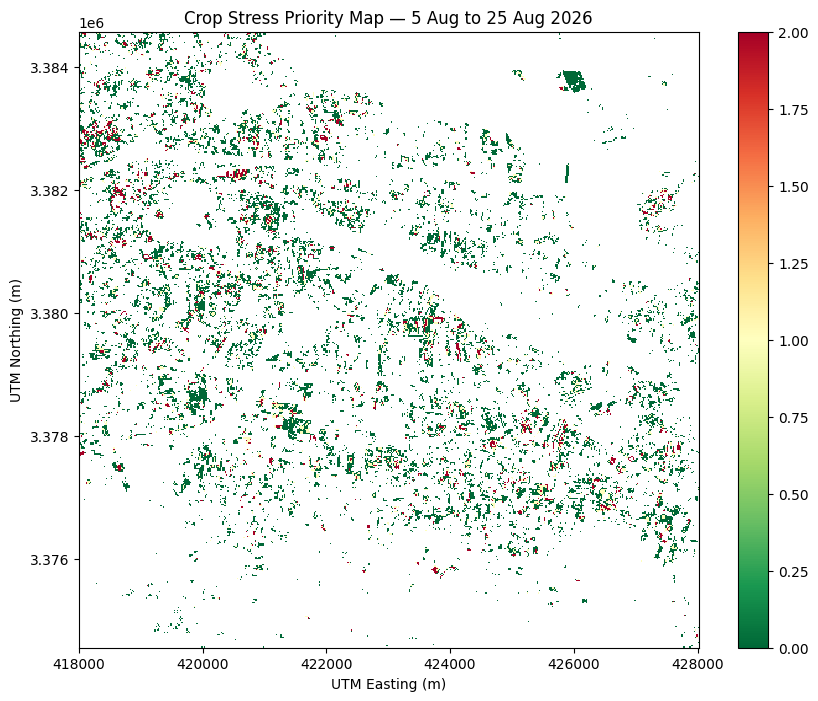

In [97]:
plt.figure(figsize=(10, 8))

priority_map.plot(
    cmap="RdYlGn_r",
    vmin=0,
    vmax=2,
    add_colorbar=True
)

plt.title("Crop Stress Priority Map — 5 Aug to 25 Aug 2026")
plt.xlabel("UTM Easting (m)")
plt.ylabel("UTM Northing (m)")

plt.show()

In [98]:
# Sentinel-2 — 16 September 2026

item_url_3 = (
    "https://planetarycomputer.microsoft.com/api/stac/v1/collections/"
    "sentinel-2-l2a/items/"
    "S2A_MSIL2A_20260916T083521_R021_T36RVU_20260916T132413"
)

fresh_item_3 = pystac.Item.from_file(item_url_3)
fresh_signed_item_3 = planetary_computer.sign(fresh_item_3)

# -------------------------
# NDVI bands: B04 + B08
# -------------------------
red_3 = rioxarray.open_rasterio(
    fresh_signed_item_3.assets["B04"].href
).squeeze()

nir_3 = rioxarray.open_rasterio(
    fresh_signed_item_3.assets["B08"].href
).squeeze()

red_aoi_3 = red_3.rio.clip_box(
    minx=x_min, miny=y_min,
    maxx=x_max, maxy=y_max
)

nir_aoi_3 = nir_3.rio.clip_box(
    minx=x_min, miny=y_min,
    maxx=x_max, maxy=y_max
)

red_float_3 = red_aoi_3.astype("float32")
nir_float_3 = nir_aoi_3.astype("float32")

ndvi_aoi_3 = (
    (nir_float_3 - red_float_3) /
    (nir_float_3 + red_float_3)
)

# -------------------------
# NDMI bands: B8A + B11
# -------------------------
b8a_3 = rioxarray.open_rasterio(
    fresh_signed_item_3.assets["B8A"].href
).squeeze()

b11_3 = rioxarray.open_rasterio(
    fresh_signed_item_3.assets["B11"].href
).squeeze()

b8a_aoi_3 = b8a_3.rio.clip_box(
    minx=x_min, miny=y_min,
    maxx=x_max, maxy=y_max
)

b11_aoi_3 = b11_3.rio.clip_box(
    minx=x_min, miny=y_min,
    maxx=x_max, maxy=y_max
)

b8a_float_3 = b8a_aoi_3.astype("float32")
b11_float_3 = b11_aoi_3.astype("float32")

ndmi_aoi_3 = (
    (b8a_float_3 - b11_float_3) /
    (b8a_float_3 + b11_float_3)
)

# -------------------------
# SCL vegetation mask
# -------------------------
scl_3 = rioxarray.open_rasterio(
    fresh_signed_item_3.assets["SCL"].href
).squeeze()

scl_aoi_3 = scl_3.rio.clip_box(
    minx=x_min, miny=y_min,
    maxx=x_max, maxy=y_max
)

scl_10m_3 = scl_aoi_3.rio.reproject_match(
    ndvi_aoi_3,
    resampling=0
)

vegetation_mask_3 = scl_10m_3 == 4

# NDMI is 20m, so convert vegetation mask to 20m
vegetation_mask_3_uint8 = vegetation_mask_3.astype("uint8")

vegetation_mask_3_20m = vegetation_mask_3_uint8.rio.reproject_match(
    ndmi_aoi_3,
    resampling=0
) == 1

# -------------------------
# Results
# -------------------------
print("NDVI 16 Sep mean:",
      ndvi_aoi_3.where(vegetation_mask_3).mean().item())

print("NDMI 16 Sep mean:",
      ndmi_aoi_3.where(vegetation_mask_3_20m).mean().item())

print("Vegetation pixels 10m:",
      vegetation_mask_3.sum().item())

print("Vegetation pixels 20m:",
      vegetation_mask_3_20m.sum().item())

NDVI 16 Sep mean: 0.37731966376304626
NDMI 16 Sep mean: 0.10478732734918594
Vegetation pixels 10m: 370860
Vegetation pixels 20m: 92874


In [99]:
ndvi_25_20m = ndvi_aoi_2.rio.reproject_match(
    ndmi_aoi_2,
    resampling=Resampling.average
)

ndvi_16_20m = ndvi_aoi_3.rio.reproject_match(
    ndmi_aoi_2,
    resampling=Resampling.average
)

ndvi_change_25_to_16 = ndvi_16_20m - ndvi_25_20m

print("NDVI Change 25 Aug → 16 Sep")
print("Min:", ndvi_change_25_to_16.min().item())
print("Max:", ndvi_change_25_to_16.max().item())
print("Mean:", ndvi_change_25_to_16.mean().item())

NDVI Change 25 Aug → 16 Sep
Min: -0.5509130954742432
Max: 0.6905920505523682
Mean: -0.027229584753513336


In [100]:
ndmi_change_25_to_16 = (
    ndmi_aoi_3 - ndmi_aoi_2
)

print("NDMI Change 25 Aug → 16 Sep")
print("Min:", ndmi_change_25_to_16.min().item())
print("Max:", ndmi_change_25_to_16.max().item())
print("Mean:", ndmi_change_25_to_16.mean().item())

NDMI Change 25 Aug → 16 Sep
Min: -0.5053597688674927
Max: 0.42781662940979004
Mean: -0.01652407832443714


In [101]:
# Common vegetation between 25 Aug and 16 Sep
common_vegetation_25_16 = (
    vegetation_mask_25_20m &
    vegetation_mask_3_20m
)

# Potential stress in period 2
potential_stress_25_16 = (
    (ndvi_change_25_to_16 < 0) &
    (ndmi_change_25_to_16 < 0) &
    common_vegetation_25_16
)

stress_pixels_25_16 = potential_stress_25_16.sum().item()
common_pixels_25_16 = common_vegetation_25_16.sum().item()

stress_pct_25_16 = (
    stress_pixels_25_16 /
    common_pixels_25_16 *
    100
)

print("Potential stress pixels:", stress_pixels_25_16)
print("Common vegetation pixels:", common_pixels_25_16)
print("Potential stress percentage:", stress_pct_25_16)

Potential stress pixels: 52664
Common vegetation pixels: 87167
Potential stress percentage: 60.41735978065093


In [102]:
# نحول الـ5 Aug → 25 Aug mask إلى شبكة 20m
stress_period_1_20m = potential_stress_mask_20m

# المناطق التي كانت Stress في الفترتين
persistent_stress = (
    stress_period_1_20m &
    potential_stress_25_16
)

persistent_pixels = persistent_stress.sum().item()

period_1_stress = stress_period_1_20m.sum().item()

print("Persistent stress pixels:", persistent_pixels)
print("Period 1 stress pixels:", period_1_stress)

print(
    "Persistence percentage:",
    persistent_pixels / period_1_stress * 100
)

Persistent stress pixels: 10473
Period 1 stress pixels: 26407
Persistence percentage: 39.65993865262998


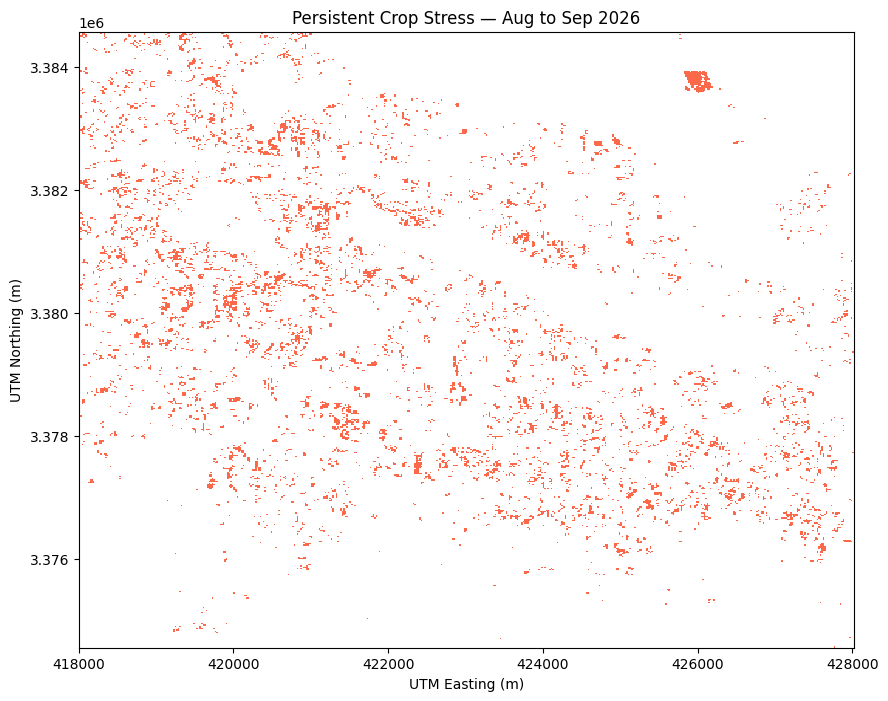

In [103]:
persistent_stress_map = xr.where(
    persistent_stress,
    1,
    np.nan
)

plt.figure(figsize=(10, 8))

persistent_stress_map.plot(
    cmap="Reds",
    add_colorbar=False
)

plt.title(
    "Persistent Crop Stress — Aug to Sep 2026"
)

plt.xlabel("UTM Easting (m)")
plt.ylabel("UTM Northing (m)")

plt.show()

In [104]:
# ==========================================
# Stress Score for Period 2
# ==========================================

ndvi_drop_25_16 = -ndvi_change_25_to_16
ndmi_drop_25_16 = -ndmi_change_25_to_16

stress_score_25_16 = (
    ndvi_drop_25_16.clip(min=0) +
    ndmi_drop_25_16.clip(min=0)
)

stress_score_25_16 = stress_score_25_16.where(
    potential_stress_25_16
)

# ==========================================
# Persistent Stress Score
# ==========================================

persistent_stress_score = (
    stress_score +
    stress_score_25_16
).where(
    persistent_stress
)

print("Persistent Stress Score min:",
      persistent_stress_score.min().item())

print("Persistent Stress Score max:",
      persistent_stress_score.max().item())

print("Persistent Stress Score mean:",
      persistent_stress_score.mean().item())

Persistent Stress Score min: 0.0041108280420303345
Persistent Stress Score max: 0.7405431270599365
Persistent Stress Score mean: 0.18367913365364075


In [105]:
persistent_values = persistent_stress_score.values
persistent_values = persistent_values[
    ~np.isnan(persistent_values)
]

persistent_percentiles = np.percentile(
    persistent_values,
    [50, 75, 90, 95]
)

print("50th percentile:", persistent_percentiles[0])
print("75th percentile:", persistent_percentiles[1])
print("90th percentile:", persistent_percentiles[2])
print("95th percentile:", persistent_percentiles[3])

50th percentile: 0.1587490737438202
75th percentile: 0.24602970480918884
90th percentile: 0.3380524218082429
95th percentile: 0.3982115387916565


In [106]:
# Final Priority thresholds
medium_threshold = 0.24602970480918884
high_threshold = 0.3380524218082429

final_priority = xr.full_like(
    persistent_stress_score,
    np.nan,
    dtype="float32"
)

# Lower Priority
final_priority = xr.where(
    persistent_stress_score < medium_threshold,
    0,
    final_priority
)

# Medium Priority
final_priority = xr.where(
    (persistent_stress_score >= medium_threshold) &
    (persistent_stress_score < high_threshold),
    1,
    final_priority
)

# High Priority
final_priority = xr.where(
    persistent_stress_score >= high_threshold,
    2,
    final_priority
)

print("Lower Priority:",
      (final_priority == 0).sum().item())

print("Medium Priority:",
      (final_priority == 1).sum().item())

print("High Priority:",
      (final_priority == 2).sum().item())

print("Total Persistent Stress:",
      (~np.isnan(final_priority.values)).sum())

Lower Priority: 7854
Medium Priority: 1571
High Priority: 1048
Total Persistent Stress: 10473


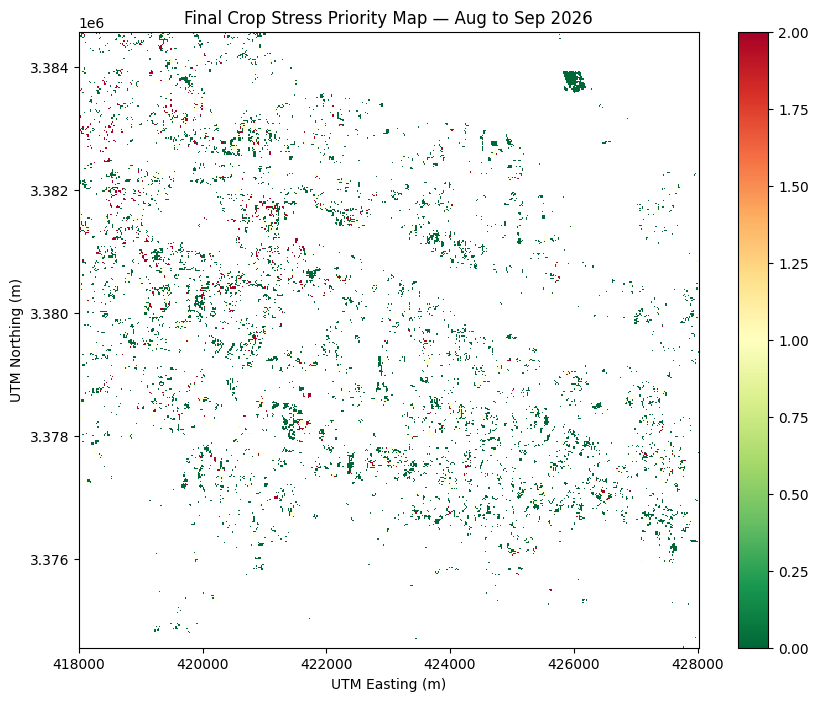

In [107]:
plt.figure(figsize=(10, 8))

final_priority.plot(
    cmap="RdYlGn_r",
    vmin=0,
    vmax=2,
    add_colorbar=True
)

plt.title(
    "Final Crop Stress Priority Map — Aug to Sep 2026"
)

plt.xlabel("UTM Easting (m)")
plt.ylabel("UTM Northing (m)")

plt.show()

In [108]:
# High Priority area
high_priority_mask = final_priority == 2

# Coordinates of High Priority pixels
high_y, high_x = np.where(
    high_priority_mask.values
)

print("High Priority pixels:", len(high_x))

print("X min:", final_priority.x.values[high_x].min())
print("X max:", final_priority.x.values[high_x].max())

print("Y min:", final_priority.y.values[high_y].min())
print("Y max:", final_priority.y.values[high_y].max())

High Priority pixels: 1048
X min: 418010.0
X max: 427830.0
Y min: 3375490.0
Y max: 3384570.0


In [109]:
from pystac_client import Client
from pyproj import Transformer

# ==========================================
# High Priority bounding box — UTM Zone 36N
# ==========================================

x_min_hp = 418010.0
x_max_hp = 427830.0
y_min_hp = 3375490.0
y_max_hp = 3384570.0

# Convert UTM 36N → WGS84
transformer = Transformer.from_crs(
    "EPSG:32636",
    "EPSG:4326",
    always_xy=True
)

lon_min, lat_min = transformer.transform(
    x_min_hp, y_min_hp
)

lon_max, lat_max = transformer.transform(
    x_max_hp, y_max_hp
)

print("WGS84 Bounding Box:")
print("Lon min:", lon_min)
print("Lon max:", lon_max)
print("Lat min:", lat_min)
print("Lat max:", lat_max)

# ==========================================
# Search EnMAP L2A STAC
# ==========================================

catalog_enmap = Client.open(
    "https://geoservice.dlr.de/eoc/ogc/stac/v1"
)

search_enmap = catalog_enmap.search(
    collections=["ENMAP_HSI_L2A"],
    bbox=[
        lon_min,
        lat_min,
        lon_max,
        lat_max
    ]
)

enmap_items = list(search_enmap.items())

print("\nEnMAP scenes found:", len(enmap_items))

for item in enmap_items[:10]:
    print(
        item.id,
        "|",
        item.datetime,
        "| Cloud:",
        item.properties.get("eo:cloud_cover")
    )

WGS84 Bounding Box:
Lon min: 32.145523705905184
Lon max: 32.247225060901215
Lat min: 30.50891644613323
Lat max: 30.591476650339175

EnMAP scenes found: 28
ENMAP01-____L2A-DT0000169419_20251218T203112Z_010_V010505_20251221T143530Z | 2025-12-18 20:31:14.278119+00:00 | Cloud: 0
ENMAP01-____L2A-DT0000168748_20251214T202734Z_010_V010505_20251217T140202Z | 2025-12-14 20:27:36.325056+00:00 | Cloud: 0
ENMAP01-____L2A-DT0000167779_20251210T202355Z_010_V010505_20251216T195632Z | 2025-12-10 20:23:57.295007+00:00 | Cloud: 0
ENMAP01-____L2A-DT0000119037_20250314T090612Z_004_V010502_20250319T195940Z | 2025-03-14 09:06:14.566529+00:00 | Cloud: 0
ENMAP01-____L2A-DT0000117024_20250219T091020Z_004_V010502_20250222T152743Z | 2025-02-19 09:10:22.612111+00:00 | Cloud: 83
ENMAP01-____L2A-DT0000117024_20250219T091015Z_003_V010502_20250222T152639Z | 2025-02-19 09:10:18.160015+00:00 | Cloud: 80
ENMAP01-____L2A-DT0000113155_20250127T091322Z_003_V010502_20250131T042207Z | 2025-01-27 09:13:25.157674+00:00 | Cloud

In [110]:
# Show EnMAP scenes from 2026 only
print("EnMAP 2026 scenes:\n")

for item in enmap_items:
    if item.datetime.year == 2026:
        print(
            item.id,
            "|",
            item.datetime,
            "| Cloud:",
            item.properties.get("eo:cloud_cover"),
            "| Quality:",
            item.properties.get("enmap:overallQuality")
        )

EnMAP 2026 scenes:



In [111]:
# Search specifically for EnMAP scenes over our High Priority area in 2026

search_enmap_2026 = catalog_enmap.search(
    collections=["ENMAP_HSI_L2A"],
    bbox=[
        lon_min,
        lat_min,
        lon_max,
        lat_max
    ],
    datetime="2026-01-01/2026-12-31"
)

enmap_2026_items = list(search_enmap_2026.items())

print("EnMAP 2026 scenes found:", len(enmap_2026_items))

for item in enmap_2026_items:
    print(
        item.id,
        "|",
        item.datetime,
        "| Cloud:",
        item.properties.get("eo:cloud_cover")
    )

EnMAP 2026 scenes found: 0


In [112]:
# Rank available EnMAP scenes by:
# 1. closeness to 16 Sep 2026
# 2. low cloud cover

from datetime import datetime, timezone

target_date = datetime(
    2026, 9, 16,
    tzinfo=timezone.utc
)

ranked_enmap = sorted(
    enmap_items,
    key=lambda item: (
        abs((item.datetime - target_date).total_seconds()),
        item.properties.get("eo:cloud_cover", 100)
    )
)

for item in ranked_enmap[:10]:
    days_diff = abs(
        (item.datetime - target_date).total_seconds()
    ) / (24 * 3600)

    print(
        item.id,
        "| Date:", item.datetime.date(),
        "| Days from target:", round(days_diff, 1),
        "| Cloud:", item.properties.get("eo:cloud_cover")
    )

ENMAP01-____L2A-DT0000169419_20251218T203112Z_010_V010505_20251221T143530Z | Date: 2025-12-18 | Days from target: 271.1 | Cloud: 0
ENMAP01-____L2A-DT0000168748_20251214T202734Z_010_V010505_20251217T140202Z | Date: 2025-12-14 | Days from target: 275.1 | Cloud: 0
ENMAP01-____L2A-DT0000167779_20251210T202355Z_010_V010505_20251216T195632Z | Date: 2025-12-10 | Days from target: 279.2 | Cloud: 0
ENMAP01-____L2A-DT0000119037_20250314T090612Z_004_V010502_20250319T195940Z | Date: 2025-03-14 | Days from target: 550.6 | Cloud: 0
ENMAP01-____L2A-DT0000117024_20250219T091020Z_004_V010502_20250222T152743Z | Date: 2025-02-19 | Days from target: 573.6 | Cloud: 83
ENMAP01-____L2A-DT0000117024_20250219T091015Z_003_V010502_20250222T152639Z | Date: 2025-02-19 | Days from target: 573.6 | Cloud: 80
ENMAP01-____L2A-DT0000113155_20250127T091322Z_003_V010502_20250131T042207Z | Date: 2025-01-27 | Days from target: 596.6 | Cloud: 11
ENMAP01-____L2A-DT0000093056_20240918T091714Z_005_V010502_20260521T013923Z | Dat

In [113]:
# Select the closest low-cloud EnMAP scene
enmap_selected = ranked_enmap[0]

print("Selected scene:")
print(enmap_selected.id)
print("Date:", enmap_selected.datetime)
print("Cloud:", enmap_selected.properties.get("eo:cloud_cover"))

print("\nAvailable assets:\n")

for key, asset in enmap_selected.assets.items():
    print(
        key,
        "|",
        asset.title,
        "|",
        asset.media_type
    )

Selected scene:
ENMAP01-____L2A-DT0000169419_20251218T203112Z_010_V010505_20251221T143530Z
Date: 2025-12-18 20:31:14.278119+00:00
Cloud: 0

Available assets:

metadata | Metadata | application/xml
image | Spectral Image | image/tiff; application=geotiff; profile=cloud-optimized
vnir | Quicklook VNIR | image/tiff; application=geotiff; profile=cloud-optimized
thumbnail | Thumbnail VNIR | image/png
swir | Quicklook SWIR | image/tiff; application=geotiff; profile=cloud-optimized
quality_classes | Quality classes | image/tiff; application=geotiff; profile=cloud-optimized
quality_cloud | Quality cloud | image/tiff; application=geotiff; profile=cloud-optimized
quality_cloud_shadow | Quality cloud shadow | image/tiff; application=geotiff; profile=cloud-optimized
quality_haze | Quality haze | image/tiff; application=geotiff; profile=cloud-optimized
quality_cirrus | Quality cirrus | image/tiff; application=geotiff; profile=cloud-optimized
quality_snow | Quality snow | image/tiff; application=geo

In [114]:
import requests

enmap_url = enmap_selected.assets["image"].href

response = requests.get(
    enmap_url,
    stream=True,
    timeout=30
)

print("HTTP status:", response.status_code)
print("Content-Type:", response.headers.get("Content-Type"))
print("Content-Length:", response.headers.get("Content-Length"))
print("First bytes:", next(response.iter_content(chunk_size=16)))

HTTP status: 200
Content-Type: text/html;charset=UTF-8
Content-Length: None
First bytes: b'<!DOCTYPE html'


In [115]:
# Test the EnMAP VNIR quicklook
quicklook_url = enmap_selected.assets["vnir"].href

response = requests.get(
    quicklook_url,
    stream=True,
    timeout=30
)

print("HTTP status:", response.status_code)
print("Content-Type:", response.headers.get("Content-Type"))
print("First bytes:", next(response.iter_content(chunk_size=16)))

HTTP status: 200
Content-Type: text/html;charset=UTF-8
First bytes: b'<!DOCTYPE html'


In [116]:
search_recent = catalog_enmap.search(
    collections=["ENMAP_HSI_L2A"],
    bbox=[
        lon_min,
        lat_min,
        lon_max,
        lat_max
    ],
    datetime="2026-08-01/2026-09-30"
)

recent_items = list(search_recent.items())

print("EnMAP L2A scenes Aug-Sep 2026:", len(recent_items))

for item in recent_items:
    print(
        item.id,
        "| Date:", item.datetime,
        "| Cloud:", item.properties.get("eo:cloud_cover")
    )

EnMAP L2A scenes Aug-Sep 2026: 0


In [117]:
import requests

catalog_url = "https://www.planet.com/data/stac/catalog.json"

response = requests.get(catalog_url)

print("Status:", response.status_code)

catalog_data = response.json()

print("Catalog type:", catalog_data.get("type"))
print("\nChildren:")

for link in catalog_data.get("links", []):
    if link.get("rel") in ["child", "item"]:
        print(link.get("rel"), "->", link.get("title"), "|", link.get("href"))

Status: 200
Catalog type: Catalog

Children:
child -> Open SkySat Data | https://www.planet.com/data/stac/open-skysat-data/collection.json
child -> Open Canada | https://www.planet.com/data/stac/open-canada/catalog.json
child -> Planet Disaster Data (small sample) | https://www.planet.com/data/stac/disasters/collection.json
child -> Spacenet 7 Data & Labels | https://www.planet.com/data/stac/spacenet7/catalog.json
child -> Planet Fusion Data (2021 Nebraska Sample) | https://www.planet.com/data/stac/fusion/14N/29E-188N/collection.json
child -> Planet University Open Data | https://www.planet.com/data/stac/education/catalog.json
child -> Planet Tanager Sample Products | https://www.planet.com/data/stac/tanager-core-imagery/catalog.json


In [118]:
import requests

agri_collection_url = (
    "https://www.planet.com/data/stac/"
    "tanager-core-imagery/agriculture/collection.json"
)

response = requests.get(agri_collection_url)

print("Status:", response.status_code)

agri_collection = response.json()

print("Collection ID:", agri_collection.get("id"))
print("Title:", agri_collection.get("title"))

print("\nLinks:")
for link in agri_collection.get("links", []):
    print(
        link.get("rel"),
        "->",
        link.get("href")
    )

Status: 200
Collection ID: agriculture
Title: Agriculture

Links:
root -> https://www.planet.com/data/stac/catalog.json
item -> https://www.planet.com/data/stac/tanager-core-imagery/agriculture/20250224_145149_32_4001/20250224_145149_32_4001.json
item -> https://www.planet.com/data/stac/tanager-core-imagery/agriculture/20250301_143913_32_4001/20250301_143913_32_4001.json
item -> https://www.planet.com/data/stac/tanager-core-imagery/agriculture/20250311_061550_53_4001/20250311_061550_53_4001.json
item -> https://www.planet.com/data/stac/tanager-core-imagery/agriculture/20250321_054913_40_4001/20250321_054913_40_4001.json
item -> https://www.planet.com/data/stac/tanager-core-imagery/agriculture/20250430_101724_87_4001/20250430_101724_87_4001.json
item -> https://www.planet.com/data/stac/tanager-core-imagery/agriculture/20250501_143138_87_4001/20250501_143138_87_4001.json
item -> https://www.planet.com/data/stac/tanager-core-imagery/agriculture/20250503_112042_00_4001/20250503_112042_00_4

In [119]:
import requests
import json

item_url = (
    "https://www.planet.com/data/stac/"
    "tanager-core-imagery/agriculture/"
    "20250916_144254_01_4001/"
    "20250916_144254_01_4001.json"
)

response = requests.get(item_url)

print("Status:", response.status_code)

item = response.json()

print("ID:", item["id"])
print("Date:", item["properties"].get("datetime"))

print("\nBounding Box:")
print(item["bbox"])

print("\nAssets:")
for name, asset in item["assets"].items():
    print(name, "->", asset.get("href"))

Status: 200
ID: 20250916_144254_01_4001
Date: 2025-09-16T14:42:54.013127Z

Bounding Box:
[-58.859267244142785, -34.97993090173719, -58.54432173629534, -34.763515172056046]

Assets:
basic_beta_udm -> https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/basic_beta_udm/20250916_144254_01_4001_basic_beta_udm.tif
basic_radiance_hdf5 -> https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/basic_radiance_hdf5/20250916_144254_01_4001_basic_radiance_hdf5.h5
basic_sr_hdf5 -> https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/basic_sr_hdf5/20250916_144254_01_4001_basic_sr_hdf5.h5
geolocation_array -> https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/geolocation_array/20250916_144254_01_4001_geolocation_array.tif
ortho_beta_udm -> https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/ortho_beta_udm/20250916_144254_01_4001_ortho_beta_udm.tif


In [120]:
import requests
from shapely.geometry import box

# Our High Priority AOI
aoi = box(
    lon_min,
    lat_min,
    lon_max,
    lat_max
)

# Get all item links from the Agriculture collection
item_links = [
    link["href"]
    for link in agri_collection["links"]
    if link.get("rel") == "item"
]

print("Total Agriculture scenes:", len(item_links))

# Check which scenes actually intersect our AOI
matching_scenes = []

for url in item_links:
    item_data = requests.get(url).json()

    scene_bbox = item_data.get("bbox")

    if scene_bbox is None:
        continue

    scene = box(
        scene_bbox[0],
        scene_bbox[1],
        scene_bbox[2],
        scene_bbox[3]
    )

    if scene.intersects(aoi):
        matching_scenes.append({
            "id": item_data["id"],
            "date": item_data["properties"].get("datetime"),
            "bbox": scene_bbox
        })

print("\nScenes covering our AOI:", len(matching_scenes))

for scene in matching_scenes:
    print(
        scene["id"],
        "|",
        scene["date"],
        "|",
        scene["bbox"]
    )

Total Agriculture scenes: 44

Scenes covering our AOI: 0


In [121]:
import numpy as np
from scipy import ndimage

# High priority pixels
high_priority_mask = (final_priority == 2).values

# Find connected regions
labeled_zones, num_zones = ndimage.label(
    high_priority_mask,
    structure=np.ones((3, 3), dtype=int)
)

print("Number of High Priority zones:", num_zones)
print("Total High Priority pixels:", high_priority_mask.sum())

Number of High Priority zones: 576
Total High Priority pixels: 1048


In [122]:
# Count pixels in each zone
zone_sizes = np.bincount(labeled_zones.ravel())

# Ignore zone 0 (background)
zone_sizes = zone_sizes[1:]

print("Total zones:", len(zone_sizes))

print("\nZone size statistics:")
print("Smallest:", zone_sizes.min(), "pixels")
print("Largest:", zone_sizes.max(), "pixels")
print("Median:", np.median(zone_sizes))
print("Mean:", zone_sizes.mean())

print("\nZones with at least:")
for threshold in [2, 5, 10, 20, 50]:
    print(
        threshold,
        "pixels:",
        np.sum(zone_sizes >= threshold)
    )

Total zones: 576

Zone size statistics:
Smallest: 1 pixels
Largest: 12 pixels
Median: 1.0
Mean: 1.8194444444444444

Zones with at least:
2 pixels: 227
5 pixels: 35
10 pixels: 3
20 pixels: 0
50 pixels: 0


In [123]:
# Zones with at least 5 pixels
large_zones = [
    (zone_id, size)
    for zone_id, size in enumerate(zone_sizes, start=1)
    if size >= 5
]

# Sort from largest to smallest
large_zones.sort(key=lambda x: x[1], reverse=True)

print("Zones with >= 5 pixels:", len(large_zones))

print("\nZone ID | Pixels | Area (hectares)")
print("-" * 40)

for zone_id, size in large_zones:
    area_m2 = size * 20 * 20
    area_ha = area_m2 / 10000

    print(
        f"{zone_id:7d} | "
        f"{size:6d} | "
        f"{area_ha:10.3f}"
    )

Zones with >= 5 pixels: 35

Zone ID | Pixels | Area (hectares)
----------------------------------------
    301 |     12 |      0.480
    347 |     12 |      0.480
    451 |     10 |      0.400
    152 |      9 |      0.360
    401 |      9 |      0.360
    490 |      9 |      0.360
     19 |      8 |      0.320
    526 |      8 |      0.320
     70 |      7 |      0.280
     93 |      7 |      0.280
    364 |      7 |      0.280
    483 |      7 |      0.280
     27 |      6 |      0.240
    219 |      6 |      0.240
    222 |      6 |      0.240
    277 |      6 |      0.240
    278 |      6 |      0.240
    285 |      6 |      0.240
    517 |      6 |      0.240
    551 |      6 |      0.240
    555 |      6 |      0.240
    183 |      5 |      0.200
    186 |      5 |      0.200
    194 |      5 |      0.200
    201 |      5 |      0.200
    209 |      5 |      0.200
    210 |      5 |      0.200
    231 |      5 |      0.200
    241 |      5 |      0.200
    292 |      5 |      0.

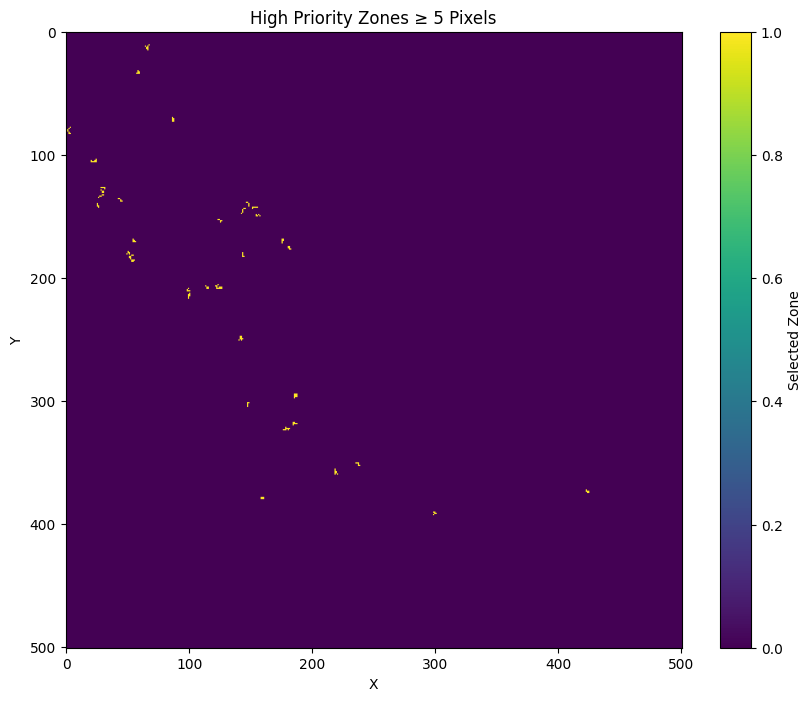

In [124]:
import matplotlib.pyplot as plt

# Keep only zones with at least 5 pixels
large_zone_mask = np.isin(
    labeled_zones,
    [zone_id for zone_id, size in large_zones]
)

plt.figure(figsize=(10, 8))

plt.imshow(
    large_zone_mask,
    cmap="viridis"
)

plt.title("High Priority Zones ≥ 5 Pixels")
plt.xlabel("X")
plt.ylabel("Y")
plt.colorbar(label="Selected Zone")

plt.show()

In [125]:
import pandas as pd
import numpy as np

# Zones with at least 5 pixels
selected_zone_ids = [
    zone_id for zone_id, size in large_zones
]

zone_records = []

for zone_id in selected_zone_ids:

    zone_mask = labeled_zones == zone_id

    # Pixel locations
    rows, cols = np.where(zone_mask)

    # Center pixel
    center_row = int(np.mean(rows))
    center_col = int(np.mean(cols))

    # Get coordinates from the stress raster
    x = persistent_stress_score.x.values[center_col]
    y = persistent_stress_score.y.values[center_row]

    # Convert UTM → Latitude / Longitude
    from pyproj import Transformer

    transformer = Transformer.from_crs(
        "EPSG:32636",
        "EPSG:4326",
        always_xy=True
    )

    lon, lat = transformer.transform(x, y)

    # Zone statistics
    pixel_count = len(rows)
    area_ha = pixel_count * 20 * 20 / 10000

    zone_scores = persistent_stress_score.values[zone_mask]
    mean_score = np.nanmean(zone_scores)

    zone_records.append({
        "Zone_ID": zone_id,
        "Pixels": pixel_count,
        "Area_ha": area_ha,
        "Latitude": lat,
        "Longitude": lon,
        "Mean_Stress_Score": mean_score
    })

zones_df = pd.DataFrame(zone_records)

# Sort by stress score
zones_df = zones_df.sort_values(
    "Mean_Stress_Score",
    ascending=False
).reset_index(drop=True)

print(zones_df.to_string(index=False))

 Zone_ID  Pixels  Area_ha  Latitude  Longitude  Mean_Stress_Score
     301      12     0.48 30.557891  32.155939           0.549362
      27       6     0.24 30.585148  32.156954           0.540465
     241       5     0.20 30.563582  32.170904           0.526585
     186       5     0.20 30.567605  32.151058           0.525441
     278       6     0.24 30.560581  32.181565           0.521360
     277       6     0.24 30.560420  32.156334           0.500474
     210       5     0.20 30.565614  32.150241           0.483029
     490       9     0.36 30.532975  32.182422           0.469084
     352       5     0.20 30.553643  32.168904           0.467008
     222       6     0.24 30.565051  32.174854           0.464797
     183       5     0.20 30.568146  32.151053           0.462377
     347      12     0.48 30.553655  32.170780           0.461232
     152       9     0.36 30.572107  32.149559           0.452752
      19       8     0.32 30.588767  32.158383           0.450753
     451  

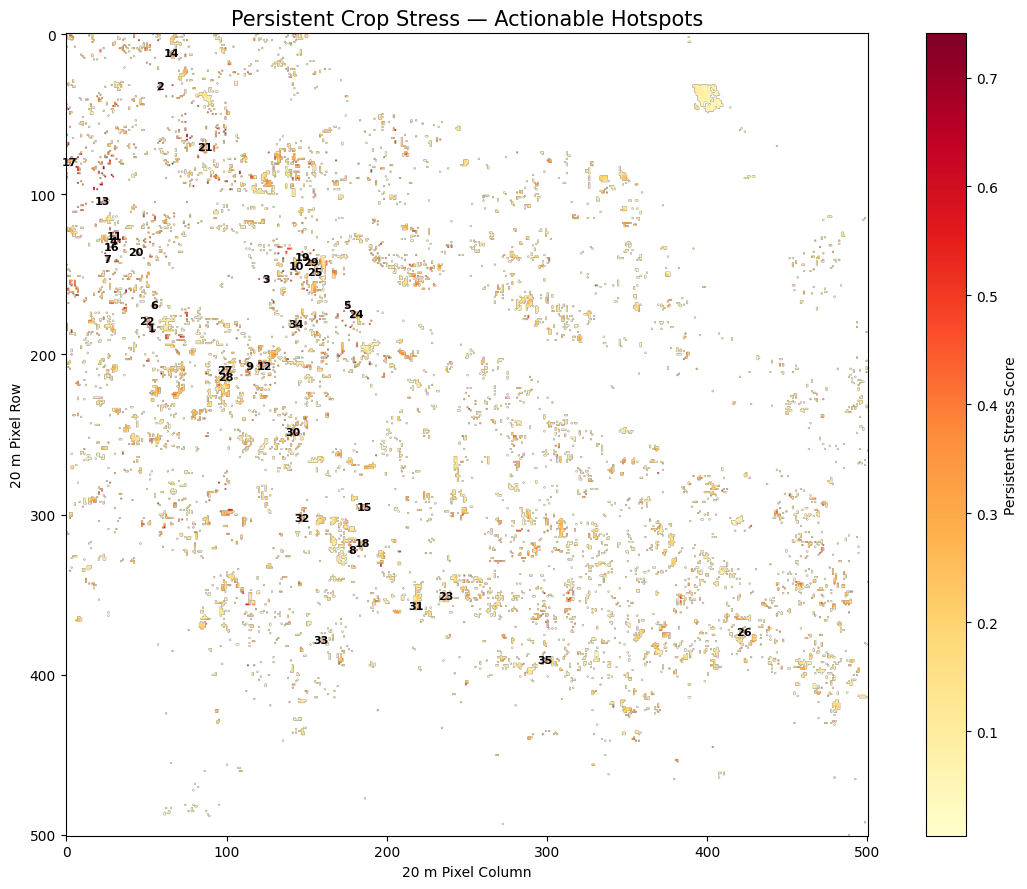

In [126]:
import matplotlib.pyplot as plt

# Create rank for each selected zone
zones_df["Rank"] = np.arange(1, len(zones_df) + 1)

# Mask containing only selected zones
selected_mask = np.isin(
    labeled_zones,
    zones_df["Zone_ID"].values
)

# Plot
fig, ax = plt.subplots(figsize=(12, 9))

# Background: persistent stress score
im = ax.imshow(
    persistent_stress_score.values,
    cmap="YlOrRd",
    origin="upper"
)

# Overlay selected hotspots
ax.imshow(
    np.where(selected_mask, 1, np.nan),
    cmap="Blues",
    alpha=0.55,
    origin="upper"
)

# Add rank labels
for _, row in zones_df.iterrows():

    zone_id = int(row["Zone_ID"])

    rows, cols = np.where(
        labeled_zones == zone_id
    )

    center_row = np.mean(rows)
    center_col = np.mean(cols)

    ax.text(
        center_col,
        center_row,
        str(int(row["Rank"])),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold"
    )

ax.set_title(
    "Persistent Crop Stress — Actionable Hotspots",
    fontsize=15
)

ax.set_xlabel("20 m Pixel Column")
ax.set_ylabel("20 m Pixel Row")

plt.colorbar(
    im,
    ax=ax,
    label="Persistent Stress Score"
)

plt.tight_layout()
plt.show()

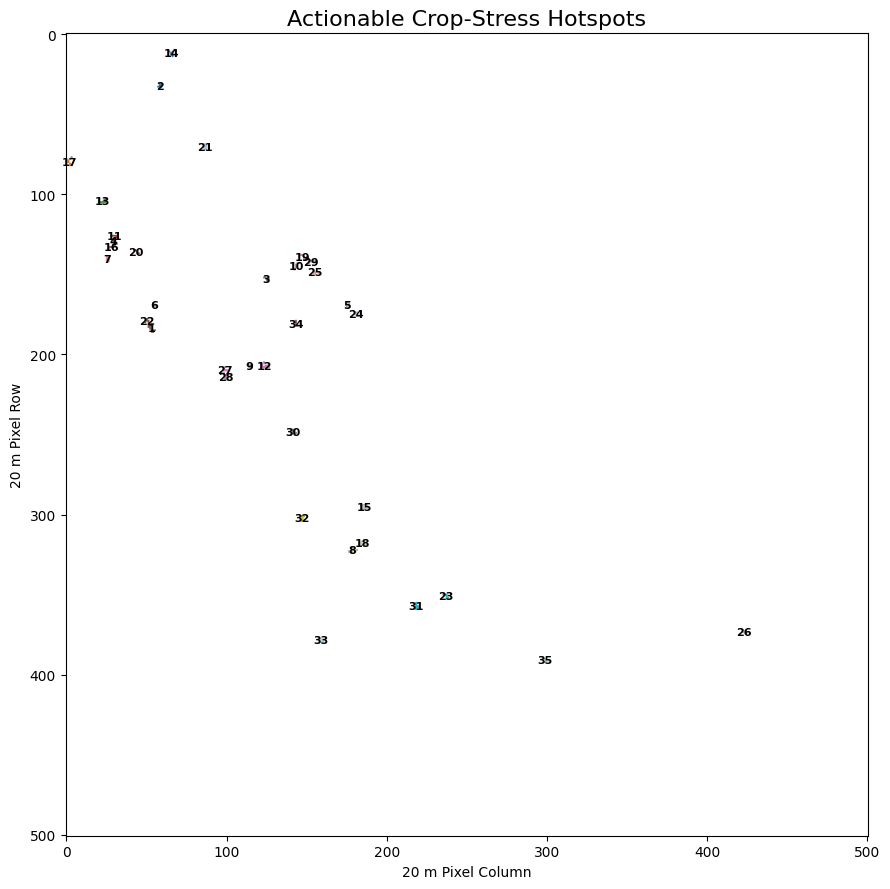

In [127]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 9))

# Show only selected actionable hotspots
hotspots_only = np.where(
    selected_mask,
    labeled_zones,
    np.nan
)

ax.imshow(
    hotspots_only,
    cmap="tab20",
    origin="upper"
)

# Add rank labels
for _, row in zones_df.iterrows():

    zone_id = int(row["Zone_ID"])

    rows, cols = np.where(
        labeled_zones == zone_id
    )

    center_row = np.mean(rows)
    center_col = np.mean(cols)

    ax.text(
        center_col,
        center_row,
        str(int(row["Rank"])),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold"
    )

ax.set_title(
    "Actionable Crop-Stress Hotspots",
    fontsize=16
)

ax.set_xlabel("20 m Pixel Column")
ax.set_ylabel("20 m Pixel Row")

plt.tight_layout()
plt.show()

In [128]:
# Create final hotspot dataset

final_hotspots_df = zones_df.copy()

# User-friendly hotspot ID
final_hotspots_df["Hotspot_ID"] = [
    f"HS-{i:02d}"
    for i in range(1, len(final_hotspots_df) + 1)
]

# All selected hotspots are High Priority
final_hotspots_df["Priority"] = "High"

# Reorder columns
final_hotspots_df = final_hotspots_df[
    [
        "Hotspot_ID",
        "Rank",
        "Zone_ID",
        "Priority",
        "Area_ha",
        "Latitude",
        "Longitude",
        "Mean_Stress_Score"
    ]
]

# Save for the future dashboard
final_hotspots_df.to_csv(
    "agri_pulse_hotspots.csv",
    index=False
)

print("Final hotspots dataset created.")
print("Number of hotspots:", len(final_hotspots_df))
print("Total hotspot area:",
      final_hotspots_df["Area_ha"].sum(),
      "ha")

print("\nPreview:")
display(final_hotspots_df.head(10))

Final hotspots dataset created.
Number of hotspots: 35
Total hotspot area: 9.159999999999998 ha

Preview:


,Hotspot_ID,Rank,Zone_ID,Priority,Area_ha,Latitude,Longitude,Mean_Stress_Score
0,HS-01,1,301,High,0.48,30.557891,32.155939,0.549362
1,HS-02,2,27,High,0.24,30.585148,32.156954,0.540465
2,HS-03,3,241,High,0.20,30.563582,32.170904,0.526585
3,HS-04,4,186,High,0.20,30.567605,32.151058,0.525441
4,HS-05,5,278,High,0.24,30.560581,32.181565,0.521360
5,HS-06,6,277,High,0.24,30.560420,32.156334,0.500474
6,HS-07,7,210,High,0.20,30.565614,32.150241,0.483029
7,HS-08,8,490,High,0.36,30.532975,32.182422,0.469084
8,HS-09,9,352,High,0.20,30.553643,32.168904,0.467008
9,HS-10,10,222,High,0.24,30.565051,32.174854,0.464797


In [129]:
# ==========================================
# AgriPulse - Dashboard Data Preparation
# ==========================================

import pandas as pd
import json

# Copy final hotspot dataset
dashboard_hotspots = final_hotspots_df.copy()

# Rename columns for the dashboard
dashboard_hotspots = dashboard_hotspots.rename(columns={
    "Hotspot_ID": "Hotspot",
    "Mean_Stress_Score": "Stress_Score",
    "Area_ha": "Area_Ha"
})

# Keep only the columns the dashboard needs
dashboard_hotspots = dashboard_hotspots[
    [
        "Hotspot",
        "Rank",
        "Priority",
        "Area_Ha",
        "Latitude",
        "Longitude",
        "Stress_Score"
    ]
]

# Round values for presentation
dashboard_hotspots["Area_Ha"] = dashboard_hotspots["Area_Ha"].round(3)
dashboard_hotspots["Latitude"] = dashboard_hotspots["Latitude"].round(6)
dashboard_hotspots["Longitude"] = dashboard_hotspots["Longitude"].round(6)
dashboard_hotspots["Stress_Score"] = dashboard_hotspots["Stress_Score"].round(4)

# Summary metrics
dashboard_summary = {
    "persistent_stress_pixels": 10473,
    "high_priority_pixels": 1048,
    "actionable_hotspots": len(dashboard_hotspots),
    "hotspot_area_ha": round(
        dashboard_hotspots["Area_Ha"].sum(), 3
    ),
    "analysis_period": "5 Aug 2026 → 16 Sep 2026",
    "aoi": "10 × 10 km — Ismailia, Egypt"
}

# Save dashboard data
dashboard_hotspots.to_csv(
    "agri_pulse_hotspots_final.csv",
    index=False
)

with open("agri_pulse_summary.json", "w") as f:
    json.dump(dashboard_summary, f, indent=4)

print("Dashboard data prepared successfully.\n")

print("SUMMARY")
print("--------------------------------")
for key, value in dashboard_summary.items():
    print(f"{key}: {value}")

print("\nDashboard table:")
display(dashboard_hotspots.head(10))

Dashboard data prepared successfully.

SUMMARY
--------------------------------
persistent_stress_pixels: 10473
high_priority_pixels: 1048
actionable_hotspots: 35
hotspot_area_ha: 9.16
analysis_period: 5 Aug 2026 → 16 Sep 2026
aoi: 10 × 10 km — Ismailia, Egypt

Dashboard table:


,Hotspot,Rank,Priority,Area_Ha,Latitude,Longitude,Stress_Score
0,HS-01,1,High,0.48,30.557891,32.155939,0.5494
1,HS-02,2,High,0.24,30.585148,32.156954,0.5405
2,HS-03,3,High,0.20,30.563582,32.170904,0.5266
3,HS-04,4,High,0.20,30.567605,32.151058,0.5254
4,HS-05,5,High,0.24,30.560581,32.181565,0.5214
5,HS-06,6,High,0.24,30.560420,32.156334,0.5005
6,HS-07,7,High,0.20,30.565614,32.150241,0.4830
7,HS-08,8,High,0.36,30.532975,32.182422,0.4691
8,HS-09,9,High,0.20,30.553643,32.168904,0.4670
9,HS-10,10,High,0.24,30.565051,32.174854,0.4648


In [130]:
# Create the initial AgriPulse Streamlit app

app_code = r'''
import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="AgriPulse",
    page_icon="🌱",
    layout="wide"
)

# -----------------------------
# Load data
# -----------------------------

hotspots = pd.read_csv(
    "agri_pulse_hotspots_final.csv"
)

# -----------------------------
# Header
# -----------------------------

st.title("🌱 AgriPulse")

st.subheader(
    "Explainable Crop Stress & Inspection Intelligence"
)

st.caption(
    "Sentinel-2 based monitoring — Ismailia, Egypt"
)

st.divider()

# -----------------------------
# KPI metrics
# -----------------------------

col1, col2, col3, col4 = st.columns(4)

with col1:
    st.metric(
        "Persistent Stress",
        "10,473 pixels"
    )

with col2:
    st.metric(
        "High Priority",
        "1,048 pixels"
    )

with col3:
    st.metric(
        "Actionable Hotspots",
        "35"
    )

with col4:
    st.metric(
        "Hotspot Area",
        "9.16 ha"
    )

st.divider()

# -----------------------------
# Dataset preview
# -----------------------------

st.header("Actionable Hotspots")

st.dataframe(
    hotspots,
    use_container_width=True,
    hide_index=True
)
'''

with open("app.py", "w") as f:
    f.write(app_code)

print("app.py created successfully.")

app.py created successfully.


In [131]:
!python -m py_compile app.py

print("app.py syntax check: OK")

app.py syntax check: OK


In [132]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 95.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 91.9 MB/s eta 0:00:00


In [133]:
!python -m streamlit run app.py &> /tmp/streamlit.log &

In [134]:
import time
import re

time.sleep(3)

with open("/tmp/streamlit.log", "r") as f:
    log = f.read()

print(log)

In [135]:
!pip install -q pyngrok

In [136]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [137]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [138]:
import requests

response = requests.get("http://localhost:8501")

print("Status:", response.status_code)
print("Content-Type:", response.headers.get("content-type"))
print(response.text[:100])

Status: 200
Content-Type: text/html; charset=utf-8
<!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apach


In [139]:
from google.colab import output

url = output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print(url)

https://8501-m-s-kkb-use4a1-2iuvbzuy7wruk-a.us-east4-1.prod.colab.dev


In [140]:
# Stop the current Streamlit server
!pkill -f "streamlit run app.py" || true

# Start Streamlit in a way that works better with Colab's proxy
!python -m streamlit run app.py \
    --server.address 0.0.0.0 \
    --server.port 8501 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /tmp/streamlit.log 2>&1 &

^C


In [141]:
import time
time.sleep(3)

!cat /tmp/streamlit.log



2026-09-20 14:50:18.901 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://8.234.232.174:8501

2026-09-20 14:50:22.662 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.


In [142]:
from google.colab import output

url = output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print(url)

https://8501-m-s-kkb-use4a1-2iuvbzuy7wruk-a.us-east4-1.prod.colab.dev


In [143]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙
added 22 packages in 3s
⠙
⠙3 packages are looking for funding
⠙  run `npm fund` for details
⠙

In [144]:
!lt --port 8501

your url is: https://wide-badgers-learn.loca.lt
^C


In [145]:
!pkill -f "streamlit run app.py" || true

^C


In [146]:
!python -m streamlit run app.py \
    --server.address 0.0.0.0 \
    --server.port 8501 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /tmp/streamlit.log 2>&1 &

In [147]:
from google.colab import files

files.download("app.py")
files.download("agri_pulse_hotspots_final.csv")
files.download("agri_pulse_summary.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [148]:
!pip install -q folium streamlit-folium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.9/536.9 kB 17.1 MB/s eta 0:00:00


In [149]:
import os

print(os.listdir())

['.config', '__pycache__', 'agri_pulse_hotspots.csv', 'agri_pulse_summary.json', 'agri_pulse_hotspots_final.csv', 'app.py', 'sample_data']


In [150]:
from pathlib import Path

print(Path("app.py").read_text())


import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="AgriPulse",
    page_icon="🌱",
    layout="wide"
)

# -----------------------------
# Load data
# -----------------------------

hotspots = pd.read_csv(
    "agri_pulse_hotspots_final.csv"
)

# -----------------------------
# Header
# -----------------------------

st.title("🌱 AgriPulse")

st.subheader(
    "Explainable Crop Stress & Inspection Intelligence"
)

st.caption(
    "Sentinel-2 based monitoring — Ismailia, Egypt"
)

st.divider()

# -----------------------------
# KPI metrics
# -----------------------------

col1, col2, col3, col4 = st.columns(4)

with col1:
    st.metric(
        "Persistent Stress",
        "10,473 pixels"
    )

with col2:
    st.metric(
        "High Priority",
        "1,048 pixels"
    )

with col3:
    st.metric(
        "Actionable Hotspots",
        "35"
    )

with col4:
    st.metric(
        "Hotspot Area",
        "9.16 ha"
    )

st.divider()

# --------------------

In [151]:
app_code = r'''
import streamlit as st
import pandas as pd
import folium
from streamlit_folium import st_folium

st.set_page_config(
    page_title="AgriPulse",
    page_icon="🌱",
    layout="wide"
)

# -----------------------------
# Load data
# -----------------------------

hotspots = pd.read_csv(
    "agri_pulse_hotspots_final.csv"
)

# -----------------------------
# Header
# -----------------------------

st.title("🌱 AgriPulse")

st.subheader(
    "Explainable Crop Stress & Inspection Intelligence"
)

st.caption(
    "Sentinel-2 based monitoring — Ismailia, Egypt"
)

st.divider()

# -----------------------------
# KPI metrics
# -----------------------------

col1, col2, col3, col4 = st.columns(4)

with col1:
    st.metric(
        "Persistent Stress",
        "10,473 pixels"
    )

with col2:
    st.metric(
        "High Priority",
        "1,048 pixels"
    )

with col3:
    st.metric(
        "Actionable Hotspots",
        "35"
    )

with col4:
    st.metric(
        "Hotspot Area",
        "9.16 ha"
    )

st.divider()

# -----------------------------
# Hotspot Map
# -----------------------------

st.header("📍 Crop-Stress Hotspots")

st.caption(
    "High-priority areas identified from persistent Sentinel-2 crop-stress indicators."
)

# Center map on Ismailia
m = folium.Map(
    location=[30.555, 32.175],
    zoom_start=12,
    tiles="OpenStreetMap"
)

# Add hotspot markers
for _, row in hotspots.iterrows():

    popup_text = f"""
    <b>{row['Hotspot_ID']}</b><br>
    Rank: {row['Rank']}<br>
    Priority: {row['Priority']}<br>
    Area: {row['Area_ha']} ha<br>
    Stress Score: {row['Mean_Stress_Score']:.4f}
    """

    folium.CircleMarker(
        location=[
            row["Latitude"],
            row["Longitude"]
        ],
        radius=7,
        popup=folium.Popup(
            popup_text,
            max_width=300
        ),
        tooltip=row["Hotspot_ID"],
        fill=True,
        fill_opacity=0.8
    ).add_to(m)

st_folium(
    m,
    width="100%",
    height=600
)

st.divider()

# -----------------------------
# Dataset preview
# -----------------------------

st.header("Actionable Hotspots")

st.dataframe(
    hotspots,
    width="stretch",
    hide_index=True
)
'''

with open("app.py", "w") as f:
    f.write(app_code)

print("app.py updated successfully ✅")

app.py updated successfully ✅


In [152]:
!pkill -f "streamlit run app.py" || true

!python -m streamlit run app.py \
    --server.address 0.0.0.0 \
    --server.port 8501 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /tmp/streamlit.log 2>&1 &

^C


In [153]:
import time
import subprocess

subprocess.Popen(
    "lt --port 8501 > /tmp/lt.log 2>&1",
    shell=True
)

time.sleep(3)

print(open("/tmp/lt.log").read())

your url is: https://green-poets-happen.loca.lt



In [154]:
hotspots = pd.read_csv("agri_pulse_hotspots_final.csv")

print(hotspots.columns.tolist())

['Hotspot', 'Rank', 'Priority', 'Area_Ha', 'Latitude', 'Longitude', 'Stress_Score']


In [155]:
app_code = r'''
import streamlit as st
import pandas as pd
import folium
from streamlit_folium import st_folium

st.set_page_config(
    page_title="AgriPulse",
    page_icon="🌱",
    layout="wide"
)

# -----------------------------
# Load data
# -----------------------------

hotspots = pd.read_csv(
    "agri_pulse_hotspots_final.csv"
)

# -----------------------------
# Header
# -----------------------------

st.title("🌱 AgriPulse")

st.subheader(
    "Explainable Crop Stress & Inspection Intelligence"
)

st.caption(
    "Sentinel-2 based monitoring — Ismailia, Egypt"
)

st.divider()

# -----------------------------
# KPI metrics
# -----------------------------

col1, col2, col3, col4 = st.columns(4)

with col1:
    st.metric(
        "Persistent Stress",
        "10,473 pixels"
    )

with col2:
    st.metric(
        "High Priority",
        "1,048 pixels"
    )

with col3:
    st.metric(
        "Actionable Hotspots",
        "35"
    )

with col4:
    st.metric(
        "Hotspot Area",
        "9.16 ha"
    )

st.divider()

# -----------------------------
# Hotspot Map
# -----------------------------

st.header("📍 Crop-Stress Hotspots")

st.caption(
    "High-priority areas identified from persistent Sentinel-2 crop-stress indicators."
)

m = folium.Map(
    location=[30.555, 32.175],
    zoom_start=12,
    tiles="OpenStreetMap"
)

# Add hotspot markers
for _, row in hotspots.iterrows():

    popup_text = f"""
    <b>{row['Hotspot']}</b><br>
    Rank: {row['Rank']}<br>
    Priority: {row['Priority']}<br>
    Area: {row['Area_Ha']} ha<br>
    Stress Score: {row['Stress_Score']:.4f}
    """

    folium.CircleMarker(
        location=[
            row["Latitude"],
            row["Longitude"]
        ],
        radius=7,
        popup=folium.Popup(
            popup_text,
            max_width=300
        ),
        tooltip=row["Hotspot"],
        fill=True,
        fill_opacity=0.8
    ).add_to(m)

st_folium(
    m,
    width="100%",
    height=600
)

st.divider()

# -----------------------------
# Dataset preview
# -----------------------------

st.header("Actionable Hotspots")

st.dataframe(
    hotspots,
    width="stretch",
    hide_index=True
)
'''

with open("app.py", "w") as f:
    f.write(app_code)

print("app.py fixed successfully ✅")

app.py fixed successfully ✅


In [156]:
!pkill -f "streamlit run app.py" || true

!python -m streamlit run app.py \
    --server.address 0.0.0.0 \
    --server.port 8501 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /tmp/streamlit.log 2>&1 &

^C


In [157]:
import time
import subprocess

subprocess.Popen(
    "lt --port 8501 > /tmp/lt.log 2>&1",
    shell=True
)

time.sleep(3)

print(open("/tmp/lt.log").read())

your url is: https://real-gifts-shop.loca.lt



In [158]:
from pathlib import Path

app = Path("app.py").read_text()

old_code = '''st.dataframe(
    hotspots,
    width="stretch",
    hide_index=True
)'''

new_code = '''st.markdown(
    hotspots.to_html(
        index=False,
        escape=False
    ),
    unsafe_allow_html=True
)'''

app = app.replace(old_code, new_code)

Path("app.py").write_text(app)

print("Table updated successfully ✅")

Table updated successfully ✅


In [159]:
!pkill -f "streamlit run app.py" || true

!python -m streamlit run app.py \
    --server.address 0.0.0.0 \
    --server.port 8501 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /tmp/streamlit.log 2>&1 &

^C


In [160]:
from pathlib import Path

app = Path("app.py").read_text()

# Replace metric section
start = app.index("# -----------------------------\n# KPI metrics")
end = app.index("st.divider()", start)

kpi_code = '''# -----------------------------
# KPI metrics
# -----------------------------

col1, col2, col3, col4 = st.columns(4)

with col1:
    st.markdown("**Persistent Stress**")
    st.markdown("### 10,473 pixels")

with col2:
    st.markdown("**High Priority**")
    st.markdown("### 1,048 pixels")

with col3:
    st.markdown("**Actionable Hotspots**")
    st.markdown("### 35")

with col4:
    st.markdown("**Hotspot Area**")
    st.markdown("### 9.16 ha")

'''

app = app[:start] + kpi_code + app[end:]

# Replace HTML table section with Markdown table
old_table = '''st.markdown(
    hotspots.to_html(
        index=False,
        escape=False
    ),
    unsafe_allow_html=True
)'''

new_table = '''# Create a simple Markdown table
table = "| Hotspot | Rank | Priority | Area (ha) | Latitude | Longitude | Stress Score |\\n"
table += "|---|---:|---|---:|---:|---:|---:|\\n"

for _, row in hotspots.iterrows():
    table += (
        f"| {row['Hotspot']} | "
        f"{row['Rank']} | "
        f"{row['Priority']} | "
        f"{row['Area_Ha']:.2f} | "
        f"{row['Latitude']:.6f} | "
        f"{row['Longitude']:.6f} | "
        f"{row['Stress_Score']:.4f} |\\n"
    )

st.markdown(table)
'''

app = app.replace(old_table, new_table)

Path("app.py").write_text(app)

print("Dashboard components updated successfully ✅")

Dashboard components updated successfully ✅


In [161]:
!pkill -f "streamlit run app.py" || true

!python -m streamlit run app.py \
    --server.address 0.0.0.0 \
    --server.port 8501 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /tmp/streamlit.log 2>&1 &

^C


In [162]:
import time
import subprocess

subprocess.Popen(
    "lt --port 8501 > /tmp/lt.log 2>&1",
    shell=True
)

time.sleep(3)

print(open("/tmp/lt.log").read())

your url is: https://neat-singers-roll.loca.lt



In [163]:
from pathlib import Path

app = Path("app.py").read_text()

insert_before = 'st.divider()\n\n# -----------------------------\n# Dataset preview'

new_section = '''st.divider()

# -----------------------------
# Analysis Information
# -----------------------------

st.header("📊 Analysis Overview")

info_col1, info_col2 = st.columns(2)

with info_col1:
    st.markdown("**Analysis Period**")
    st.markdown("5 Aug 2026 → 16 Sep 2026")

    st.markdown("**Area of Interest (AOI)**")
    st.markdown("10 × 10 km — Ismailia, Egypt")

with info_col2:
    st.markdown("**Data Source**")
    st.markdown("Sentinel-2 Level-2A")

    st.markdown("**Indicators Used**")
    st.markdown("NDVI + NDMI + SCL vegetation mask")

st.divider()

# -----------------------------
# Methodology
# -----------------------------

st.header("🧠 Methodology")

st.markdown("""
**Sentinel-2 Multi-Date Imagery**
↓
**Vegetation Mask using SCL**
↓
**NDVI + NDMI Calculation**
↓
**Temporal Change Detection**
↓
**Potential Crop-Stress Identification**
↓
**Persistent Stress Detection across two periods**
↓
**Stress Score Calculation**
↓
**High-Priority Hotspot Extraction**
↓
**Interactive Map for Field Inspection / Irrigation Assessment**
""")

st.divider()

# -----------------------------
# Important Note
# -----------------------------

st.header("⚠️ Interpretation Note")

st.info(
    "AgriPulse identifies areas showing persistent remote-sensing indicators "
    "of potential crop stress. These results are intended to prioritize "
    "field inspection and irrigation assessment, not to confirm crop stress "
    "or irrigation requirements without ground validation."
)

st.divider()

# -----------------------------
# Dataset preview'''

if insert_before not in app:
    print("Target section not found ❌")
else:
    app = app.replace(insert_before, new_section)
    Path("app.py").write_text(app)
    print("Methodology section added successfully ✅")

Methodology section added successfully ✅


In [164]:
!pkill -f "streamlit run app.py" || true

!python -m streamlit run app.py \
    --server.address 0.0.0.0 \
    --server.port 8501 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /tmp/streamlit.log 2>&1 &

^C


In [165]:
import time
import subprocess

subprocess.Popen(
    "lt --port 8501 > /tmp/lt.log 2>&1",
    shell=True
)

time.sleep(3)

print(open("/tmp/lt.log").read())

your url is: https://nine-rooms-hang.loca.lt



In [168]:
lines = [
    "# 🌱 AgriPulse",
    "",
    "## Explainable Crop Stress & Inspection Intelligence",
    "",
    "AgriPulse is a remote-sensing based crop monitoring system designed to identify areas showing persistent indicators of potential crop stress and prioritize them for field inspection and irrigation assessment.",
    "",
    "## 🎯 Problem",
    "",
    "Agricultural managers need to know which areas may require closer inspection.",
    "",
    "AgriPulse analyzes multi-date Sentinel-2 imagery to detect persistent changes in vegetation and moisture-related indicators.",
    "",
    "## 💡 Solution",
    "",
    "- Sentinel-2 Level-2A imagery",
    "- NDVI",
    "- NDMI",
    "- SCL vegetation masking",
    "- Multi-date change detection",
    "- Persistent stress detection",
    "- Stress scoring",
    "- High-priority hotspot extraction",
    "- Interactive geographic visualization",
    "",
    "## 🛰️ Data",
    "",
    "**Analysis Period:** 5 August 2026 → 16 September 2026",
    "",
    "**Area of Interest:** 10 × 10 km — Ismailia, Egypt",
    "",
    "Selected observations:",
    "- 5 August 2026",
    "- 25 August 2026",
    "- 16 September 2026",
    "",
    "## 🔬 Methodology",
    "",
    "1. Sentinel-2 multi-date imagery selection",
    "2. Vegetation masking using SCL",
    "3. NDVI calculation",
    "4. NDMI calculation",
    "5. Temporal change detection",
    "6. Potential crop-stress identification",
    "7. Persistent stress detection",
    "8. Stress score calculation",
    "9. High-priority hotspot extraction",
    "10. Interactive map visualization",
    "",
    "## 📊 Results",
    "",
    "| Metric | Result |",
    "|---|---:|",
    "| Persistent Stress | 10,473 pixels |",
    "| High Priority | 1,048 pixels |",
    "| Actionable Hotspots | 35 |",
    "| Hotspot Area | 9.16 ha |",
    "",
    "## 🗺️ Dashboard",
    "",
    "The AgriPulse dashboard provides:",
    "- Key performance indicators",
    "- Interactive crop-stress map",
    "- Hotspot locations",
    "- Hotspot ranking",
    "- Area of each hotspot",
    "- Stress score",
    "- Latitude and longitude",
    "- Analysis methodology",
    "",
    "## ⚠️ Interpretation",
    "",
    "AgriPulse identifies areas showing persistent remote-sensing indicators of potential crop stress.",
    "",
    "The results are intended to prioritize field inspection and irrigation assessment.",
    "",
    "They do not confirm crop stress or irrigation requirements without ground validation.",
    "",
    "## 🧰 Technologies",
    "",
    "- Python",
    "- Pandas",
    "- Xarray",
    "- Rasterio / Rioxarray",
    "- Sentinel-2",
    "- Streamlit",
    "- Folium",
    "- OpenStreetMap",
    "",
    "## 📁 Project Structure",
    "",
    "```text",
    "AgriPulse/",
    "├── AgriPulse_Project.ipynb",
    "├── app.py",
    "├── agri_pulse_hotspots_final.csv",
    "├── agri_pulse_summary.json",
    "├── README.md",
    "└── sample_data/",
    "```",
    "",
    "## 🚀 Running the Dashboard",
    "",
    "```bash",
    "pip install streamlit pandas folium streamlit-folium",
    "streamlit run app.py",
    "```",
    "",
    "## 🌱 Future Improvements",
    "",
    "- Hyperspectral observations where available",
    "- Additional temporal observations",
    "- Field-level ground validation",
    "- Weather and irrigation data integration",
    "- Machine-learning based stress classification",
    "- Automated monitoring and alerts",
    "",
    "## 👥 Project",
    "",
    "**AgriPulse — Explainable Crop Stress & Inspection Intelligence**",
    "",
    "Precision Agriculture & Crop Intelligence"
]

with open("README.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

print("README.md created successfully ✅")

README.md created successfully ✅


In [169]:
import os

files = [
    "AgriPulse_Project.ipynb",
    "app.py",
    "agri_pulse_hotspots_final.csv",
    "agri_pulse_summary.json",
    "README.md"
]

for file in files:
    print(("✅ " if os.path.exists(file) else "❌ ") + file)

❌ AgriPulse_Project.ipynb
✅ app.py
✅ agri_pulse_hotspots_final.csv
✅ agri_pulse_summary.json
✅ README.md


In [170]:
requirements = [
    "streamlit",
    "pandas",
    "folium",
    "streamlit-folium",
    "numpy",
    "xarray",
    "rioxarray",
    "rasterio",
    "pystac-client",
    "planetary-computer",
    "shapely",
    "scipy",
    "requests"
]

with open("requirements.txt", "w") as f:
    f.write("\n".join(requirements))

print("requirements.txt created successfully ✅")

requirements.txt created successfully ✅


In [171]:
import os
import zipfile

project_files = [
    "app.py",
    "agri_pulse_hotspots_final.csv",
    "agri_pulse_summary.json",
    "README.md",
    "requirements.txt"
]

with zipfile.ZipFile("AgriPulse_Project.zip", "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in project_files:
        if os.path.exists(file):
            zipf.write(file)

print("AgriPulse_Project.zip created successfully ✅")

AgriPulse_Project.zip created successfully ✅


In [174]:
from google.colab import files

files.download("AgriPulse_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [175]:
from google.colab import files
files.download("AgriPulse_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [177]:
from google.colab import files

files.download("/content/AgriPulse_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [178]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [179]:
from google.colab import files

files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>